# XGBoost：课程四维分析完整版（中文注释）

基于原 blackbox 的目标、9 个原始特征和经济规则扩展。**这是新实验，不能沿用旧输出。**
还款为 1；预测还款概率达到阈值才批准。只处理 XGBoost，不修改其他分支。

**新增内容**：XPER、PDP/ICE、LIME、解释方法分歧、客户案例；共同样本上的解释距离、
决策一致性、输入扰动与稳定性约束实验；FPDP、候选变量诊断、公平性缓解对照、
条件统计平等、分箱 Sufficiency、批准率/TPR/FPR 等效检验；四维取舍与导出。

运行：使用现有项目 Python 环境，把 `PROJECT_ROOT` 指向包含 `data/` 的项目。
安装依赖：`numpy pandas scipy scikit-learn xgboost shap matplotlib joblib`。
LIME 和 XPER 在本文件内实现透明的估计器，不依赖额外的 lime/XPER 包。
默认 `MODE="full"`；`smoke` 仅用于流程检查，不能作为正式项目结论。
首次运行需重训多个模型，XPER 还会评估全部 512 个特征联盟，请等待各节进度。

**实验边界**：训练池先隔离共同 comparison 10% 和 audit 10%；剩余 80% 每个种子分为
fit 60%、early-stop 10%、threshold 10%（比例相对于整个训练池）。comparison 用于探索
和选择方案，audit 用于冻结方案后的开发审计，共享 test 只在最后报告。
原共享测试集此前已被团队探索过，新的切分不能消除这种历史使用；最终报告须披露。

所有新增图表、模型和 CSV 写入当前工作目录下的独立运行目录，不覆盖原结果。
课件页码指 PDF 阅读器页码；括号内为幻灯片印刷页码。

In [1]:
from pathlib import Path
from itertools import combinations
from math import comb
import json, hashlib, uuid, warnings
from datetime import datetime, timezone
from importlib.metadata import version
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.special import expit
from scipy.stats import chi2, chi2_contingency, norm, spearmanr
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss, roc_curve
from sklearn.linear_model import Ridge
from IPython.display import display, Markdown
from xgboost import XGBClassifier
import xgboost as xgb
import shap
import joblib

PROJECT_ROOT = Path(r"E:\VSCodeWorkSpace\isaf-project")  # 换电脑时改为数据所在项目根目录。
MODE = "full"  # full=正式规模；smoke=真实数据小样本流程验证，不能用于正式比较。
assert MODE in {"full", "smoke"}
SEED = 42
SEEDS = [1, 10, 42, 100, 2026] if MODE == "full" else [1, 42]
N_ESTIMATORS = 1500 if MODE == "full" else 100
EARLY_STOPPING = 50 if MODE == "full" else 12
N_JOBS = 4
SAMPLE_LIMIT = None if MODE == "full" else 15000
EXPLAIN_N = 1000 if MODE == "full" else 150
PERM_REPEATS = 5 if MODE == "full" else 2
GRID_SIZE = 12 if MODE == "full" else 5
FPDP_N = 5000 if MODE == "full" else 800
XPER_N = 512 if MODE == "full" else 96
XPER_DRAWS = 8 if MODE == "full" else 2
LIME_N = 3000 if MODE == "full" else 600
BOOTSTRAP_B = 200 if MODE == "full" else 30
THRESHOLDS = np.linspace(0, 1, 101)  # 显式加入全批准边界，另加全拒绝策略。
THRESHOLDS = np.r_[THRESHOLDS, np.nextafter(1., 2.)]
DELTA, ALPHA, MIN_GROUP_N = 0.02, 0.05, 30
STABILITY_LAMBDA = 0.05  # 预先固定，不根据共享测试集调节。
MAX_AUC_LOSS, MAX_PNL_LOSS = 0.01, 0.05  # 缓解选择规则：AUC 最多降 0.01，正收益最多降 5%。
BASE = ["annual_income", "debt_to_income_ratio", "credit_score", "loan_amount",
        "interest_rate", "loan_purpose", "grade_subgrade"]
FEATURES = BASE + ["employment_status", "education_level"]
CAT = ["loan_purpose", "grade_subgrade", "employment_status", "education_level"]
NUM = [c for c in FEATURES if c not in CAT]
AUDIT = ["gender", "marital_status", "employment_status", "education_level"]
TARGET, ID = "loan_paid_back", "id"
RUN_ID = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ") + "_" + uuid.uuid4().hex[:6]
OUT = Path.cwd() / "blackbox_extended_runs" / MODE / RUN_ID
OUT.mkdir(parents=True, exist_ok=False)
TABLES = {}
plt.rcParams.update({"figure.figsize": (9, 4.8), "axes.spines.top": False,
                     "axes.spines.right": False, "figure.dpi": 110})

def table(name, data, show=True):
    """统一保存完整表格；界面只预览前 20 行，不丢弃其他结果。"""
    data = pd.DataFrame(data)
    TABLES[name] = data
    data.to_csv(OUT / (name + ".csv"), index=False, encoding="utf-8-sig")
    if show:
        display(data.head(20))
    return data

def figure(name):
    plt.tight_layout()
    plt.savefig(OUT / (name + ".png"), dpi=150, bbox_inches="tight")
    plt.show()
    plt.close()

print("模式:", MODE, "| 输出:", OUT)
print("还款为正类；候选模型只在 comparison 上选择，audit/test 留到冻结方案之后。")

模式: full | 输出: e:\VSCodeWorkSpace\isaf-project\MLModels\blackbox_extended_runs\full\20260923T191454Z_f24ed1
还款为正类；候选模型只在 comparison 上选择，audit/test 留到冻结方案之后。


e:\VSCodeWorkSpace\isaf-project\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. 数据边界与固定留出集
课件 p.17（8）区分变量、预测、决策与真实结果。20k 隔离来自小组协议。
类别集合、标准化/分箱边界、背景样本均从训练数据获得；不使用共享测试集生成这些对象。

In [2]:
full = pd.read_csv(PROJECT_ROOT / "data/train.csv")
shared_test = pd.read_csv(PROJECT_ROOT / "data/test_eval_20k.csv")
required = set(FEATURES + AUDIT + [TARGET, ID])
for frame in (full, shared_test):
    assert required.issubset(frame.columns)
    assert frame[ID].notna().all() and frame[ID].is_unique
    assert frame[TARGET].isin([0, 1]).all()
    assert not frame[list(required)].isna().any().any(), "发现缺失值，需要先制定处理规则。"
    assert np.isfinite(frame[NUM]).all().all()
    assert (frame[["loan_amount", "interest_rate"]] >= 0).all().all()
assert len(shared_test) == 20000
assert shared_test[ID].isin(full[ID]).all()
pd.testing.assert_frame_equal(full.set_index(ID).loc[shared_test[ID]].reset_index(),
                              shared_test, check_dtype=False)
pool = full.loc[~full[ID].isin(shared_test[ID])].copy()
assert not pool[ID].isin(shared_test[ID]).any()
if SAMPLE_LIMIT is not None and len(pool) > SAMPLE_LIMIT:
    pool, _ = train_test_split(pool, train_size=SAMPLE_LIMIT, stratify=pool[TARGET], random_state=SEED)
core, held = train_test_split(pool, test_size=.20, stratify=pool[TARGET], random_state=SEED)
comparison, audit = train_test_split(held, test_size=.50, stratify=held[TARGET], random_state=SEED+1)
for a, b in combinations([core, comparison, audit, shared_test], 2):
    assert not set(a[ID]) & set(b[ID])

def split_core(seed):
    # core 占训练池 80%；其中 75%/12.5%/12.5% -> 总体 60%/10%/10%。
    fit, rest = train_test_split(core, test_size=.25, stratify=core[TARGET], random_state=seed)
    es, thr = train_test_split(rest, test_size=.5, stratify=rest[TARGET], random_state=seed+1)
    return fit, es, thr

splits = {s: split_core(s) for s in SEEDS}
table("partition_sizes", [{"Partition": k, "Rows": len(v)} for k,v in
    [("core",core),("comparison",comparison),("audit",audit),("shared_test",shared_test)]])
for seed, frames in splits.items():
    manifest = pd.concat([f[[ID]].assign(Partition=label) for label,f in
        zip(["fit","early_stop","threshold"],frames)] +
        [comparison[[ID]].assign(Partition="comparison"), audit[[ID]].assign(Partition="audit")])
    manifest.to_csv(OUT / f"split_ids_{seed}.csv", index=False)

,Partition,Rows
0,core,459195
1,comparison,57399
2,audit,57400
3,shared_test,20000


## 2. 经济规则、模型包装和评价工具
p.202（169）：P&L 依赖决定和结果；60% 损失率是项目假设。
保留原 XGBoost 参数。类别取值列表只由各自 fit 样本学习，预测时保持一致。

In [3]:
def profits(df, approve):
    y = df[TARGET].to_numpy(int)
    amt, rate = df["loan_amount"].to_numpy(), df["interest_rate"].to_numpy()
    return np.asarray(approve) * np.where(y == 1, amt * rate / 100., -.60 * amt)

def threshold_search(df, p):
    rows = [{"Threshold": float(t), "PNL": float(profits(df,p>=t).sum()),
             "Approval": float(np.mean(p>=t))} for t in THRESHOLDS]
    curve = pd.DataFrame(rows)
    # 并列收益取网格中第一个阈值，确保规则确定。
    return float(curve.loc[curve.PNL.idxmax(), "Threshold"]), curve

def metrics(df, p, threshold):
    y, a = df[TARGET].to_numpy(int), np.asarray(p)>=threshold
    fpr,tpr,_ = roc_curve(y,p)
    return {"N":len(df), "AUC":roc_auc_score(y,p), "AP_repaid":average_precision_score(y,p),
            "AP_default":average_precision_score(1-y,1-p), "Gini":2*roc_auc_score(y,p)-1,
            "KS":np.max(tpr-fpr), "Brier":brier_score_loss(y,p),
            "Accuracy":np.mean(a==y), "PNL":profits(df,a).sum(),
            "PNL_per_applicant":profits(df,a).mean(), "Approval":a.mean(),
            "Default_among_approved":np.mean(y[a]==0) if a.any() else np.nan,
            "Threshold":threshold}

def encode(df, bundle):
    X = df[bundle["features"]].copy()
    for col in bundle["features"]:
        if col not in bundle["categories"]:
            X[col] = pd.to_numeric(X[col], errors="raise")
    for col, levels in bundle["categories"].items():
        X[col] = pd.Categorical(X[col], categories=levels)
    return X

def predict(bundle, df, margin=False):
    X = encode(df,bundle)
    raw = bundle["model"].get_booster().predict(
        xgb.DMatrix(X,enable_categorical=True), output_margin=True,
        iteration_range=(0,bundle["model"].best_iteration+1))
    return raw if margin else expit(raw)

def fit_bundle(seed, features=FEATURES, weight=None, anchor=None, strength=0., training_frames=None):
    fit,es,thr = splits[seed] if training_frames is None else training_frames
    categories = {c:sorted(fit[c].unique()) for c in features if c in CAT}
    bundle = {"features":list(features),"categories":categories,"seed":seed}
    objective = "binary:logistic"
    if anchor is not None:
        # 稳定性约束的函数空间扩展：CE(y,sigmoid(z)) + lambda/2 * (z-z_ref)^2。
        # p.228（194）惩罚解释距离；此处改惩罚同一输入的原始分数距离，并明确区别。
        ref = predict(anchor, fit, margin=True)
        def objective(y, z):
            p = expit(z)
            return p-y+strength*(z-ref), p*(1-p)+strength
    model = XGBClassifier(objective=objective, eval_metric="auc", n_estimators=N_ESTIMATORS,
        max_depth=5, learning_rate=.05, min_child_weight=5, subsample=.8,
        colsample_bytree=.8, reg_alpha=.5, reg_lambda=5., scale_pos_weight=1.,
        enable_categorical=True, tree_method="hist", early_stopping_rounds=EARLY_STOPPING,
        random_state=seed, n_jobs=N_JOBS)
    model.fit(encode(fit,bundle),fit[TARGET],sample_weight=weight,
              eval_set=[(encode(es,bundle),es[TARGET])],verbose=False)
    bundle["model"] = model
    bundle["threshold"], bundle["threshold_curve"] = threshold_search(thr,predict(bundle,thr))
    return bundle

## 3. 基准模型、共同验证表现和经济阈值
五个种子均使用同一 comparison 样本。最终基准种子事先固定为 42，不择优挑种子。
此处只展示开发结果，最后才读取共享测试的预测结果。

基准模型完成 1 trees= 1326
基准模型完成 10 trees= 1032
基准模型完成 42 trees= 1072
基准模型完成 100 trees= 817
基准模型完成 2026 trees= 940


,Seed,N,AUC,AP_repaid,AP_default,Gini,KS,Brier,Accuracy,PNL,PNL_per_applicant,Approval,Default_among_approved,Threshold
0,1,57399,0.920473,0.974747,0.831265,0.840946,0.677393,0.072354,0.851182,5.204737e+07,906.764433,0.725622,0.052101,0.82
1,10,57399,0.920080,0.974528,0.830949,0.840161,0.677656,0.072390,0.845746,5.210610e+07,907.787588,0.716633,0.050275,0.83
2,42,57399,0.920415,0.974668,0.831120,0.840830,0.679955,0.072361,0.845729,5.210608e+07,907.787168,0.717033,0.050538,0.83
3,100,57399,0.920113,0.974555,0.830986,0.840226,0.679330,0.072420,0.843273,5.201055e+07,906.122992,0.713671,0.050142,0.83
4,2026,57399,0.919871,0.974451,0.830371,0.839741,0.677107,0.072518,0.858308,5.220634e+07,909.533938,0.736023,0.053590,0.81


,index,mean,std,min,max
0,N,5.739900e+04,0.000000,5.739900e+04,5.739900e+04
1,AUC,9.201904e-01,0.000250,9.198707e-01,9.204731e-01
2,AP_repaid,9.745896e-01,0.000117,9.744505e-01,9.747466e-01
3,AP_default,8.309382e-01,0.000341,8.303711e-01,8.312654e-01
4,Gini,8.403809e-01,0.000501,8.397414e-01,8.409462e-01
5,KS,6.782881e-01,0.001271,6.771068e-01,6.799553e-01
6,Brier,7.240877e-02,0.000067,7.235423e-02,7.251826e-02
7,Accuracy,8.488475e-01,0.006028,8.432725e-01,8.583076e-01
8,PNL,5.209529e+07,74231.694777,5.201055e+07,5.220634e+07
9,PNL_per_applicant,9.075992e+02,1.293258,9.061230e+02,9.095339e+02


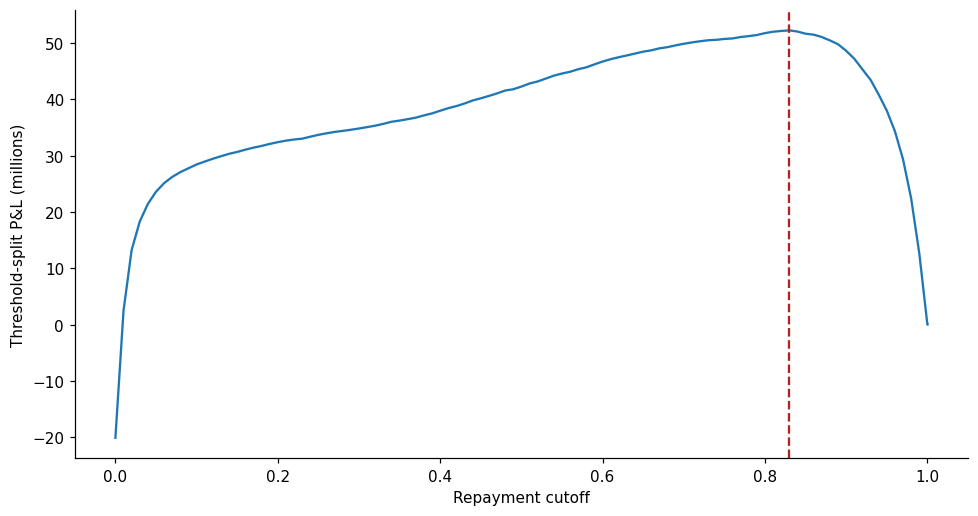

,Policy,PNL
0,Approve all,-2.039572e+07
1,Reject all,0.000000e+00
2,Fixed validation threshold,5.210608e+07


,Policy,PNL
0,Approve all,-2.039572e+07
1,Reject all,0.000000e+00
2,Fixed validation threshold,5.210608e+07


In [4]:
models = {}
for seed in SEEDS:
    models[seed] = fit_bundle(seed)
    print("基准模型完成",seed,"trees=",models[seed]["model"].best_iteration+1, flush=True)
baseline = models[SEED]
p_comp = predict(baseline,comparison)
performance = table("seed_performance", [dict(Seed=s,**metrics(comparison,predict(m,comparison),m["threshold"]))
                                             for s,m in models.items()])
table("seed_performance_summary",performance.drop(columns="Seed").agg(["mean","std","min","max"]).T.reset_index())
curve = baseline["threshold_curve"]
table("baseline_threshold_curve",curve,False)
plt.plot(curve.Threshold,curve.PNL/1e6)
plt.axvline(baseline["threshold"],c="firebrick",ls="--")
plt.xlabel("Repayment cutoff"); plt.ylabel("Threshold-split P&L (millions)")
figure("threshold_curve")
table("economic_references_comparison",[
    {"Policy":"Approve all","PNL":profits(comparison,np.ones(len(comparison),bool)).sum()},
    {"Policy":"Reject all","PNL":0},
    {"Policy":"Fixed validation threshold","PNL":profits(comparison,p_comp>=baseline["threshold"]).sum()}])

## 4. 群体指标与推断工具
p.276（240）Statistical Parity 比较批准率；p.278（242）Separation 比较 TPR/FPR。
p.310、314–315（272、276–277）TOST：两个单侧检验都拒绝，才支持差异在 ±delta 内。
这里用正态近似，不用课件的有限样本 t 临界值。Holm 校正是本项目补充。

In [5]:
def holm(values):
    p = np.asarray(values,float)
    finite = np.isfinite(p)
    result = np.full(len(p),np.nan)
    if finite.any():
        v=p[finite]; order=np.argsort(v); adj=np.empty(len(v))
        adj[order]=np.minimum(1,np.maximum.accumulate((len(v)-np.arange(len(v)))*v[order]))
        result[finite]=adj
    return result

def group_metrics(df,p,threshold):
    y,a = df[TARGET].to_numpy(int),np.asarray(p)>=threshold
    rows=[]
    for attr in AUDIT:
        for group in sorted(df[attr].unique()):
            m=(df[attr].to_numpy()==group); pos=m&(y==1); neg=m&(y==0)
            rows.append({"Attribute":attr,"Group":group,"N":int(m.sum()),
                "Approved":int(a[m].sum()),"Repaid_N":int(pos.sum()),"Default_N":int(neg.sum()),
                "Approved_repaid":int(a[pos].sum()),"Approved_default":int(a[neg].sum()),
                "Approval":a[m].mean(),"TPR":a[pos].mean() if pos.any() else np.nan,
                "FPR":a[neg].mean() if neg.any() else np.nan,
                "Precision":y[m&a].mean() if (m&a).any() else np.nan,
                "Brier":np.mean((np.asarray(p)[m]-y[m])**2),
                "AUC":roc_auc_score(y[m],np.asarray(p)[m]) if len(np.unique(y[m]))==2 else np.nan})
    return pd.DataFrame(rows)

def gaps(details):
    rows=[]
    for attr,g in details.groupby("Attribute",sort=False):
        # 小群体保留在详细表；选择方案的差距只使用预先规定的最小样本量。
        g=g[g.N>=MIN_GROUP_N]
        row={"Attribute":attr,"Eligible_groups":len(g)}
        for col in ["Approval","TPR","FPR"]:
            row[col+"_gap"]=g[col].max()-g[col].min() if len(g)>=2 else np.nan
        row["EO_gap"]=max(row["TPR_gap"],row["FPR_gap"])
        row["DI_ratio"]=g.Approval.min()/g.Approval.max() if len(g)>=2 and g.Approval.max()>0 else np.nan
        rows.append(row)
    return pd.DataFrame(rows)

def equivalence_tests(details):
    # CI90 为未作多重校正的逐对区间；正式等效结论仅使用下方 Holm 校正后的 p 值。
    rows=[]
    for attr,g in details.groupby("Attribute"):
        for (_,a),(_,b) in combinations(list(g.iterrows()),2):
            for metric,k,n in [("Approval","Approved","N"),("TPR","Approved_repaid","Repaid_N"),
                                ("FPR","Approved_default","Default_N")]:
                na,nb=float(a[n]),float(b[n]); ka,kb=float(a[k]),float(b[k])
                diff=ka/na-kb/nb if min(na,nb)>0 else np.nan
                ok=min(na,nb)>=MIN_GROUP_N and min(ka,na-ka,kb,nb-kb)>=5
                se=np.sqrt(ka/na*(1-ka/na)/na+kb/nb*(1-kb/nb)/nb) if ok else np.nan
                pv=max(norm.sf((diff+DELTA)/se),norm.cdf((diff-DELTA)/se)) if ok and se>0 else np.nan
                rows.append(dict(Attribute=attr,Group_A=a.Group,Group_B=b.Group,Metric=metric,
                    Difference=diff,N_A=na,N_B=nb,Delta=DELTA,p_raw=pv,
                    CI90_low=diff-1.644854*se,CI90_high=diff+1.644854*se))
    out=pd.DataFrame(rows);out["p_Holm"]=holm(out.p_raw)
    out["Conclusion"]=np.where(out.p_Holm.isna(),"not assessed: sparse counts",
                           np.where(out.p_Holm<ALPHA,"equivalent within delta","equivalence not established"))
    return out

fair_comp=group_metrics(comparison,p_comp,baseline["threshold"])
table("fairness_comparison",fair_comp)
table("fairness_gaps_comparison",gaps(fair_comp))
table("tost_comparison",equivalence_tests(fair_comp))

,Attribute,Group,N,Approved,Repaid_N,Default_N,Approved_repaid,Approved_default,Approval,TPR,FPR,Precision,Brier,AUC
0,gender,Female,29429,21176,23638,5791,20131,1045,0.719562,0.851637,0.180452,0.950652,0.071261,0.920509
1,gender,Male,27596,19704,21908,5688,18682,1022,0.714017,0.852748,0.179677,0.948132,0.073513,0.920378
2,gender,Other,374,277,306,68,264,13,0.740642,0.862745,0.191176,0.953069,0.073875,0.915609
3,marital_status,Divorced,2051,1466,1639,412,1386,80,0.714773,0.845638,0.194175,0.945430,0.077906,0.903314
4,marital_status,Married,26741,19221,21356,5385,18258,963,0.718784,0.854935,0.178830,0.949899,0.072295,0.921540
5,marital_status,Single,27979,20017,22351,5628,19002,1015,0.715429,0.850163,0.180348,0.949293,0.072227,0.920281
6,marital_status,Widowed,628,453,506,122,431,22,0.721338,0.851779,0.180328,0.951435,0.063020,0.931316
7,employment_status,Employed,43479,35254,38846,4633,33402,1852,0.810828,0.859857,0.399741,0.947467,0.076723,0.830106
8,employment_status,Retired,1583,1583,1580,3,1580,3,1.000000,1.000000,1.000000,0.998105,0.001892,0.803165
9,employment_status,Self-employed,5125,4186,4599,526,3972,214,0.816780,0.863666,0.406844,0.948877,0.074549,0.834490


,Attribute,Eligible_groups,Approval_gap,TPR_gap,FPR_gap,EO_gap,DI_ratio
0,gender,3,0.026625,0.011108,0.011500,0.011500,0.964051
1,marital_status,4,0.006564,0.009298,0.015345,0.015345,0.990900
2,employment_status,5,0.990445,0.894027,0.999460,0.999460,0.009555
3,education_level,5,0.051761,0.045997,0.089258,0.089258,0.931740


,Attribute,Group_A,Group_B,Metric,Difference,N_A,N_B,Delta,p_raw,CI90_low,CI90_high,p_Holm,Conclusion
0,education_level,Bachelor's,High School,Approval,-0.026240,26876.0,17757.0,0.02,0.925269,-0.033361,-0.019119,1.000000,equivalence not established
1,education_level,Bachelor's,High School,TPR,-0.011116,21220.0,14416.0,0.02,0.009751,-0.017372,-0.004861,0.604538,equivalence not established
2,education_level,Bachelor's,High School,FPR,-0.011803,5656.0,3341.0,0.02,0.165614,-0.025679,0.002073,1.000000,equivalence not established
3,education_level,Bachelor's,Master's,Approval,-0.008740,26876.0,9044.0,0.02,0.020285,-0.017784,0.000304,1.000000,equivalence not established
4,education_level,Bachelor's,Master's,TPR,-0.004670,21220.0,7232.0,0.02,0.000771,-0.012633,0.003293,0.052428,equivalence not established
5,education_level,Bachelor's,Master's,FPR,0.008899,5656.0,1812.0,0.02,0.136133,-0.007733,0.025531,1.000000,equivalence not established
6,education_level,Bachelor's,Other,Approval,-0.000434,26876.0,2638.0,0.02,0.017564,-0.015709,0.014842,1.000000,equivalence not established
7,education_level,Bachelor's,Other,TPR,0.014340,21220.0,2111.0,0.02,0.251980,0.000408,0.028272,1.000000,equivalence not established
8,education_level,Bachelor's,Other,FPR,-0.023675,5656.0,527.0,0.02,0.580365,-0.053480,0.006129,1.000000,equivalence not established
9,education_level,Bachelor's,PhD,Approval,-0.051761,26876.0,1084.0,0.02,0.991547,-0.073632,-0.029891,1.000000,equivalence not established


,Attribute,Group_A,Group_B,Metric,Difference,N_A,N_B,Delta,p_raw,CI90_low,CI90_high,p_Holm,Conclusion
0,education_level,Bachelor's,High School,Approval,-0.026240,26876.0,17757.0,0.02,0.925269,-0.033361,-0.019119,1.000000,equivalence not established
1,education_level,Bachelor's,High School,TPR,-0.011116,21220.0,14416.0,0.02,0.009751,-0.017372,-0.004861,0.604538,equivalence not established
2,education_level,Bachelor's,High School,FPR,-0.011803,5656.0,3341.0,0.02,0.165614,-0.025679,0.002073,1.000000,equivalence not established
3,education_level,Bachelor's,Master's,Approval,-0.008740,26876.0,9044.0,0.02,0.020285,-0.017784,0.000304,1.000000,equivalence not established
4,education_level,Bachelor's,Master's,TPR,-0.004670,21220.0,7232.0,0.02,0.000771,-0.012633,0.003293,0.052428,equivalence not established
...,...,...,...,...,...,...,...,...,...,...,...,...,...
82,marital_status,Married,Widowed,TPR,0.003157,21356.0,506.0,0.02,0.145916,-0.023126,0.029439,1.000000,equivalence not established
83,marital_status,Married,Widowed,FPR,-0.001498,5385.0,122.0,0.02,0.299556,-0.059392,0.056396,1.000000,equivalence not established
84,marital_status,Single,Widowed,Approval,-0.005908,27979.0,628.0,0.02,0.218032,-0.035668,0.023852,1.000000,equivalence not established
85,marital_status,Single,Widowed,TPR,-0.001615,22351.0,506.0,0.02,0.124903,-0.027892,0.024662,1.000000,equivalence not established


## 5. SHAP、置换重要性与解释方法分歧
p.188（155）检查可加性；p.190（157）用平均绝对 SHAP 汇总全局重要性。
p.207（174）置换重要性衡量表现下降。两者单位和问题不同，比较排名而非原始数值。
同一 explain 样本对所有种子固定；类别不人为编码成有序数值。

,Feature,PI_mean,PI_std,Mean_abs_SHAP,PI_rank,SHAP_rank,Rank_difference
7,employment_status,0.173275,0.012993,1.282608,1.0,1.0,0.0
1,debt_to_income_ratio,0.097325,0.012326,0.894952,2.0,2.0,0.0
2,credit_score,0.032150,0.016261,0.612743,3.0,3.0,0.0
6,grade_subgrade,0.004757,0.001839,0.203260,4.0,4.0,0.0
3,loan_amount,0.000609,0.001670,0.110426,7.0,5.0,2.0
0,annual_income,0.003686,0.001617,0.092802,5.0,6.0,1.0
4,interest_rate,0.000040,0.001767,0.090506,9.0,7.0,2.0
8,education_level,0.000512,0.001190,0.053776,8.0,8.0,0.0
5,loan_purpose,0.001658,0.001221,0.051548,6.0,9.0,3.0


PI/SHAP 排名 Spearman: 0.8499999999999999


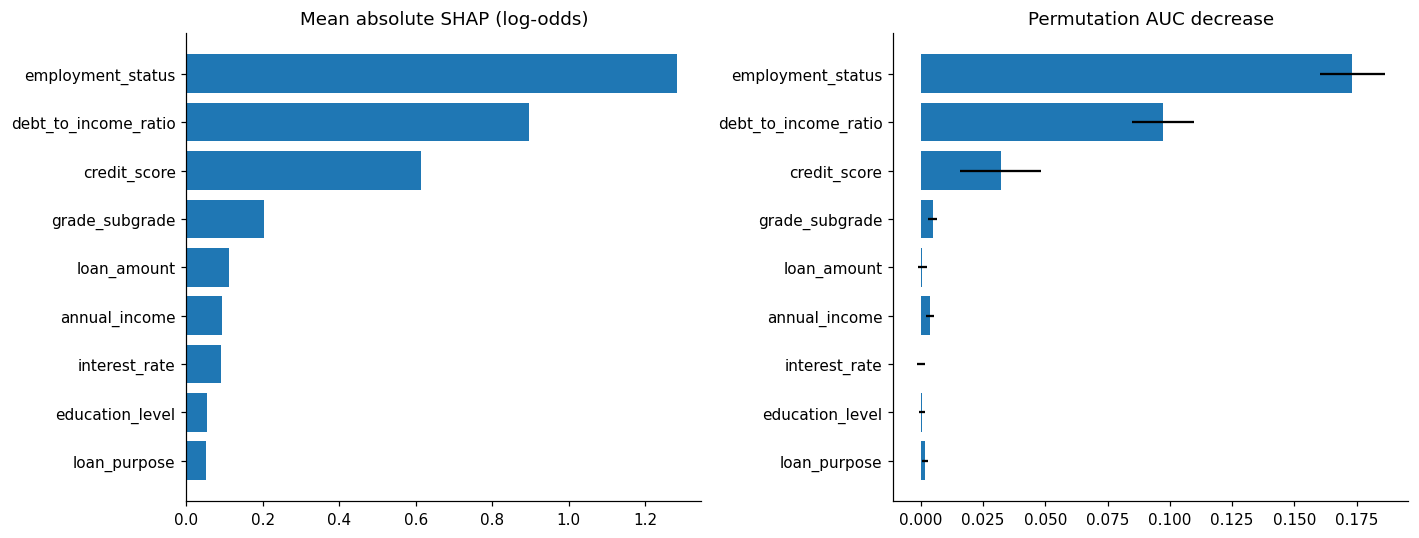

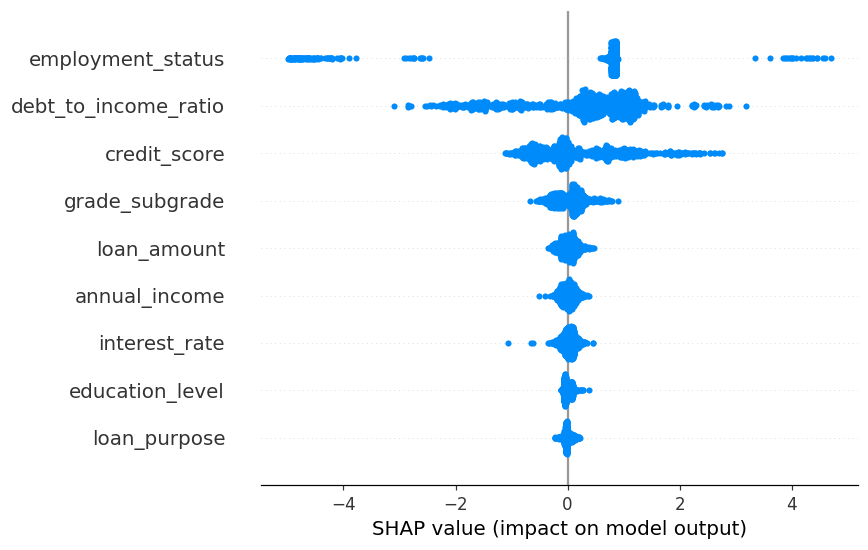

排名差异反映预测贡献与表现依赖的区别，不是自动认定某种解释错误。


In [6]:
explain_df=comparison.sample(min(EXPLAIN_N,len(comparison)),random_state=SEED)
def contributions(bundle,df):
    dm=xgb.DMatrix(encode(df,bundle),enable_categorical=True)
    c=bundle["model"].get_booster().predict(dm,pred_contribs=True,
               iteration_range=(0,bundle["model"].best_iteration+1))
    np.testing.assert_allclose(c.sum(axis=1),predict(bundle,df,True),rtol=1e-4,atol=1e-4)
    return c[:,:-1],c[:,-1]

def permutation_scores(bundle,df):
    y=df[TARGET].to_numpy(); original=roc_auc_score(y,predict(bundle,df)); rng=np.random.default_rng(SEED)
    rows=[]
    for c in bundle["features"]:
        drops=[]
        for _ in range(PERM_REPEATS):
            shuffled=df.copy();shuffled[c]=rng.permutation(shuffled[c].to_numpy())
            drops.append(original-roc_auc_score(y,predict(bundle,shuffled)))
        rows.append({"Feature":c,"PI_mean":np.mean(drops),"PI_std":np.std(drops,ddof=1)})
    return pd.DataFrame(rows)

shap_values,shap_base=contributions(baseline,explain_df)
importance=permutation_scores(baseline,explain_df)
importance["Mean_abs_SHAP"]=np.abs(shap_values).mean(axis=0)
importance["PI_rank"]=importance.PI_mean.rank(ascending=False)
importance["SHAP_rank"]=importance.Mean_abs_SHAP.rank(ascending=False)
importance["Rank_difference"]=(importance.PI_rank-importance.SHAP_rank).abs()
table("importance_and_disagreement",importance.sort_values("SHAP_rank"))
print("PI/SHAP 排名 Spearman:",spearmanr(importance.PI_rank,importance.SHAP_rank).statistic)
plot=importance.sort_values("Mean_abs_SHAP")
fig,axes=plt.subplots(1,2,figsize=(13,5))
axes[0].barh(plot.Feature,plot.Mean_abs_SHAP);axes[0].set_title("Mean absolute SHAP (log-odds)")
axes[1].barh(plot.Feature,plot.PI_mean,xerr=plot.PI_std);axes[1].set_title("Permutation AUC decrease")
figure("importance_methods")
shap.summary_plot(shap_values,feature_names=FEATURES,show=False)
figure("shap_beeswarm")
print("排名差异反映预测贡献与表现依赖的区别，不是自动认定某种解释错误。")

## 6. PDP 与 ICE：特征变化时预测怎样变化
PDP 对固定样本的预测取平均；ICE 保留每个客户的曲线。二者都不是因果效应。
分位点网格从 fit 学习；只改变一个特征，可能产生现实中罕见的组合。
数值变量画 PDP+ICE；类别变量画 PDP，不将类别之间连成连续数值。

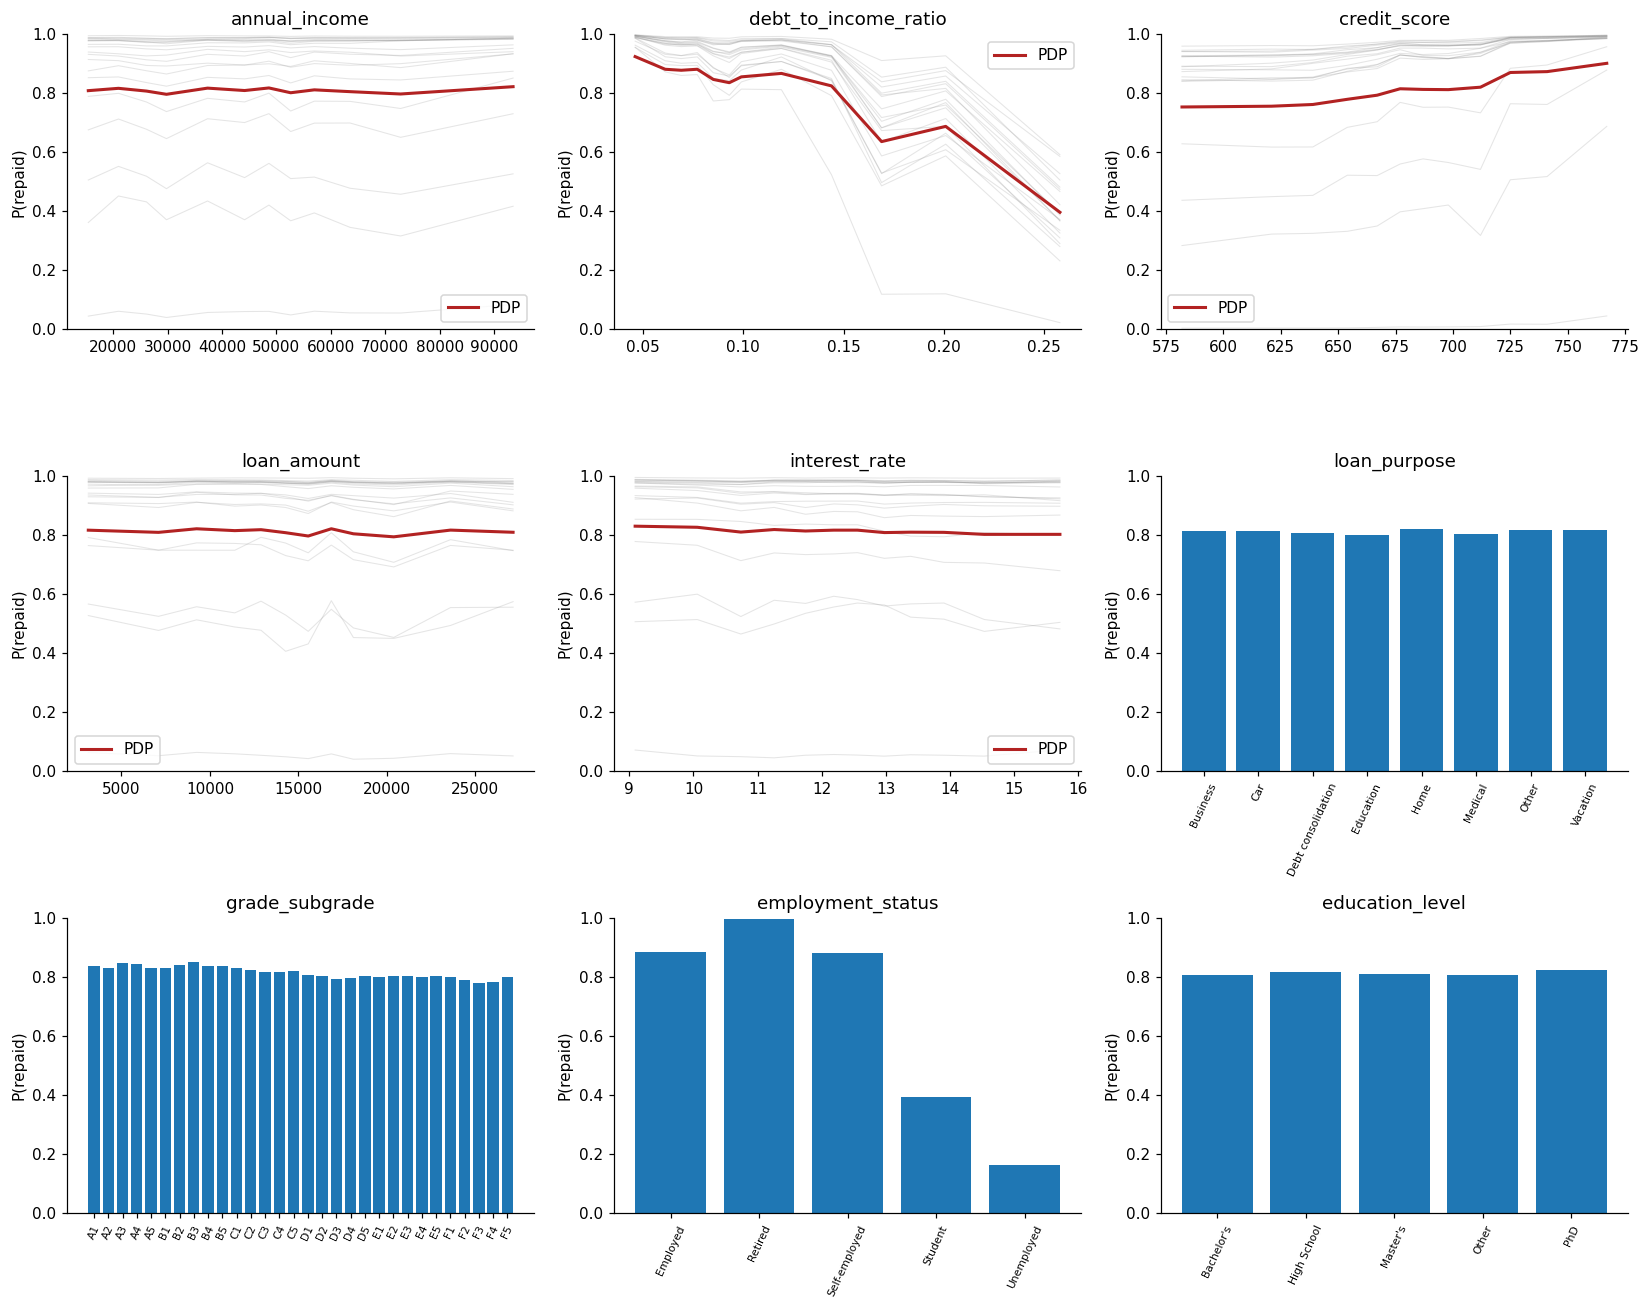

,Feature,Value,PDP_repaid
0,annual_income,15441.665,0.808664
1,annual_income,20987.88,0.816569
2,annual_income,26131.37,0.807239
3,annual_income,29803.85,0.796341
4,annual_income,37356.75,0.817231
...,...,...,...
103,education_level,Bachelor's,0.806705
104,education_level,High School,0.815301
105,education_level,Master's,0.810327
106,education_level,Other,0.807428


In [7]:
fit42,es42,thr42=splits[SEED]
def feature_grid(col):
    return sorted(fit42[col].unique()) if col in CAT else np.unique(np.quantile(fit42[col],np.linspace(.05,.95,GRID_SIZE)))

pdp_rows=[]
fig,axes=plt.subplots(3,3,figsize=(15,12))
for col,ax in zip(FEATURES,axes.ravel()):
    grid=feature_grid(col); curves=[]
    for v in grid:
        changed=explain_df.copy();changed[col]=v
        curves.append(predict(baseline,changed))
    curves=np.asarray(curves)
    for v,values in zip(grid,curves):
        pdp_rows.append({"Feature":col,"Value":v,"PDP_repaid":values.mean()})
    if col in CAT:
        ax.bar(range(len(grid)),curves.mean(axis=1));ax.set_xticks(range(len(grid)),grid,rotation=65,fontsize=7)
    else:
        ax.plot(grid,curves[:,:min(20,len(explain_df))],c="grey",alpha=.2,lw=.7)
        ax.plot(grid,curves.mean(axis=1),c="firebrick",lw=2,label="PDP");ax.legend()
    ax.set_title(col);ax.set_ylabel("P(repaid)");ax.set_ylim(0,1)
figure("pdp_ice")
table("pdp_values",pdp_rows,False)

## 7. 三个客户案例与 LIME 局部近似
p.41（19）要求解释具体决定。案例为低还款概率、高还款概率、最接近阈值者。
每个案例包含原始输入、预测概率、阈值、决定、SHAP 贡献及中文说明。

**LIME 实现说明**：使用训练集统计量产生数值扰动和类别经验分布扰动；类别用“是否与
当前客户相同”的指示变量，连续变量用标准化局部变化；以距离核加权 Ridge 拟合黑箱概率。
这是透明的 LIME 局部代理实现，非官方 lime 包默认离散化配置；输出独立扰动验证 R²与
原点误差。不把低保真度的代理解释当作模型事实。LIME 概率系数与 SHAP log-odds 不可直接比值。

,id,P_repaid,Threshold,Decision,LIME_holdout_R2,LIME_at_instance,LIME_point_error,annual_income,debt_to_income_ratio,credit_score,loan_amount,interest_rate,loan_purpose,grade_subgrade,employment_status,education_level
0,574776,0.000612,0.83,Reject,0.492203,-0.069505,0.070117,9094.26,0.426,554,15789.19,17.03,Debt consolidation,F3,Unemployed,Bachelor's


客户 574776：还款概率 0.1%，阈值 83.0%，拒绝。主要贡献：employment_status=Unemployed 降低还款倾向；debt_to_income_ratio=0.426 降低还款倾向；credit_score=554 降低还款倾向。
LIME 独立扰动 R²=0.492，原点误差=0.0701；仅解释模型行为。


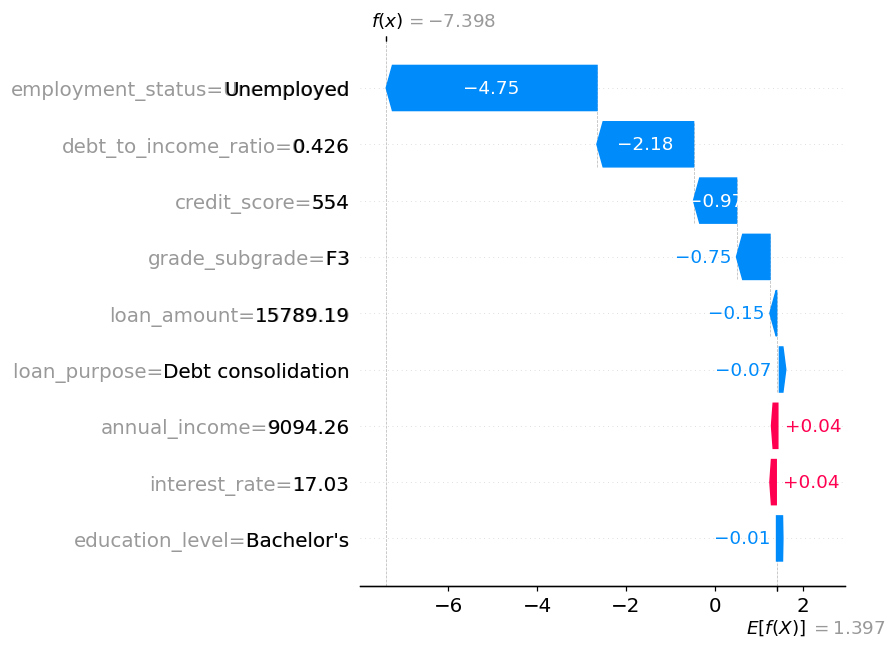

,id,P_repaid,Threshold,Decision,LIME_holdout_R2,LIME_at_instance,LIME_point_error,annual_income,debt_to_income_ratio,credit_score,loan_amount,interest_rate,loan_purpose,grade_subgrade,employment_status,education_level
0,4841,0.999906,0.83,Approve,0.07655,1.008085,0.00818,76748.44,0.03,732,12081.49,7.69,Home,C3,Retired,Master's


客户 4841：还款概率 100.0%，阈值 83.0%，批准。主要贡献：employment_status=Retired 提高还款倾向；debt_to_income_ratio=0.03 提高还款倾向；credit_score=732 提高还款倾向。
LIME 独立扰动 R²=0.077，原点误差=0.0082；仅解释模型行为。


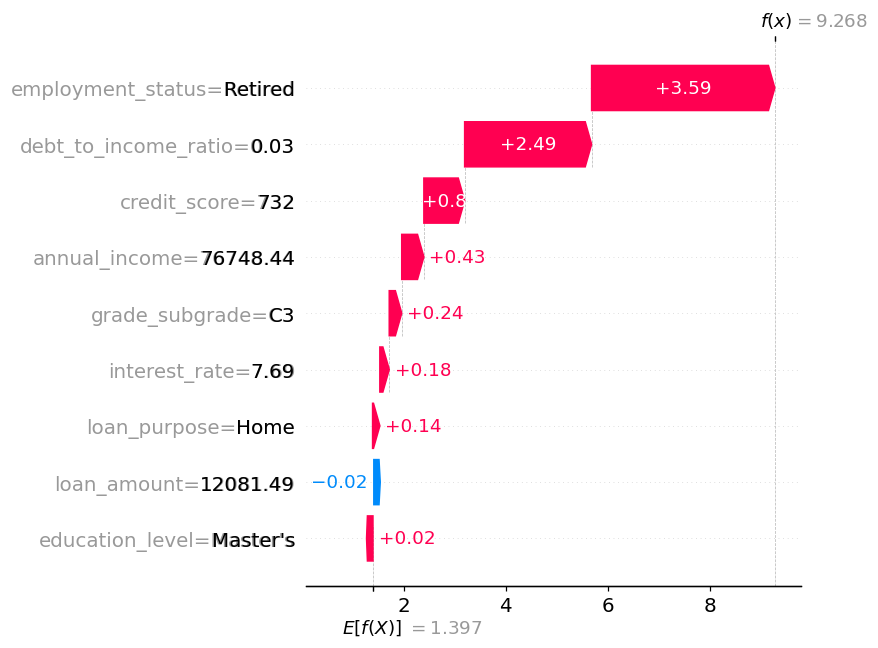

,id,P_repaid,Threshold,Decision,LIME_holdout_R2,LIME_at_instance,LIME_point_error,annual_income,debt_to_income_ratio,credit_score,loan_amount,interest_rate,loan_purpose,grade_subgrade,employment_status,education_level
0,143970,0.830002,0.83,Approve,0.454212,0.882942,0.052939,43876.54,0.076,556,18287.75,17.94,Education,F4,Employed,Bachelor's


客户 143970：还款概率 83.0%，阈值 83.0%，批准。主要贡献：debt_to_income_ratio=0.076 提高还款倾向；employment_status=Employed 提高还款倾向；credit_score=556 降低还款倾向。
LIME 独立扰动 R²=0.454，原点误差=0.0529；仅解释模型行为。


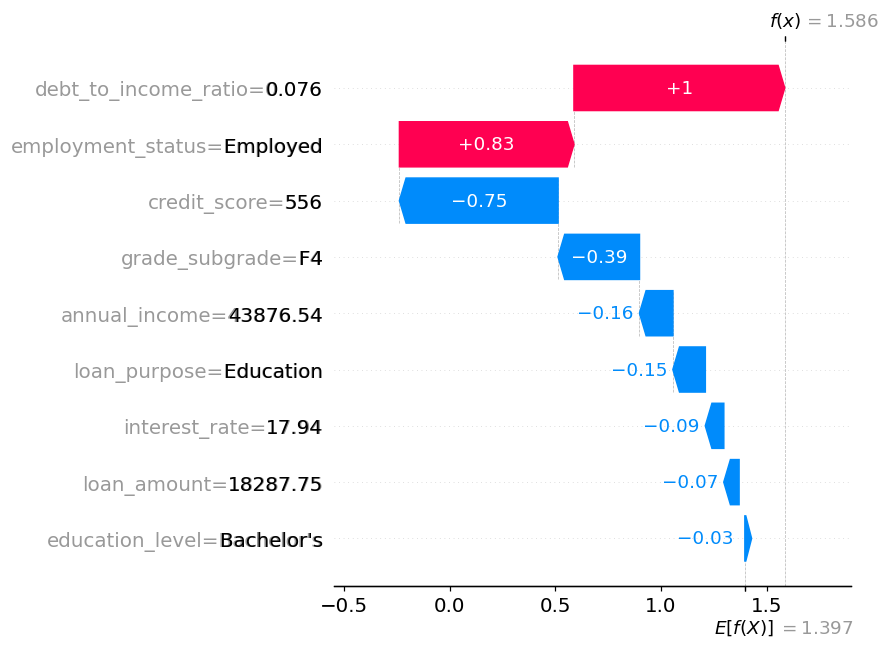

,Feature,Value,SHAP_logodds,LIME_coefficient,id
0,annual_income,9094.26,0.038129,0.010130,574776
1,debt_to_income_ratio,0.426,-2.176312,-0.029723,574776
2,credit_score,554,-0.968776,0.041579,574776
3,loan_amount,15789.19,-0.149998,0.019556,574776
4,interest_rate,17.03,0.035744,0.009302,574776
5,loan_purpose,Debt consolidation,-0.065256,-0.025353,574776
6,grade_subgrade,F3,-0.752431,-0.069191,574776
7,employment_status,Unemployed,-4.747481,-0.381045,574776
8,education_level,Bachelor's,-0.008863,0.007708,574776
9,annual_income,76748.44,0.433637,0.001291,4841


In [8]:
case_pos=list(dict.fromkeys([int(np.argmin(p_comp)),int(np.argmax(p_comp)),
                            int(np.argmin(abs(p_comp-baseline["threshold"])))]))
cases=comparison.iloc[case_pos].copy()
case_contrib,case_base=contributions(baseline,cases)
def lime_local(bundle,row,seed):
    rng=np.random.default_rng(seed); features=bundle["features"]
    scales=fit42[NUM].std().replace(0,1)
    def neighborhood(n):
        raw=pd.concat([row.to_frame().T]*n,ignore_index=True)
        z=np.zeros((n,len(features)))
        for j,c in enumerate(features):
            if c in CAT:
                raw[c]=rng.choice(fit42[c].to_numpy(),n,replace=True)
                z[:,j]=(raw[c].to_numpy()==row[c]).astype(float)
            else:
                vals=rng.normal(float(row[c]),float(scales[c]),n)
                vals=np.clip(vals,float(fit42[c].min()),float(fit42[c].max()))
                raw[c]=vals;z[:,j]=(vals-float(row[c]))/float(scales[c])
        center=np.array([1. if c in CAT else 0. for c in features])
        distance=np.linalg.norm(z-center,axis=1)
        weights=np.exp(-distance**2/(.75*np.sqrt(len(features)))**2)
        return raw,z,weights,center
    raw,z,w,center=neighborhood(LIME_N)
    raw.iloc[0]=row;z[0]=center;w[0]=1
    target=predict(bundle,raw)
    surrogate=Ridge(alpha=1.).fit(z,target,sample_weight=w)
    vr,vz,vw,_=neighborhood(max(200,LIME_N//3));vy=predict(bundle,vr)
    vp=surrogate.predict(vz);denom=np.sum(vw*(vy-np.average(vy,weights=vw))**2)
    r2=1-np.sum(vw*(vy-vp)**2)/denom if denom>0 else np.nan
    local_p=float(surrogate.predict(center[None,:])[0]); true_p=float(predict(bundle,row.to_frame().T)[0])
    return surrogate.coef_,r2,local_p,true_p

case_rows=[];local_rows=[]
for i,(_,row) in enumerate(cases.iterrows()):
    p=float(predict(baseline,row.to_frame().T)[0]);t=baseline["threshold"]
    lime_coef,r2,lp,_=lime_local(baseline,row,SEED+i)
    record={ID:row[ID],"P_repaid":p,"Threshold":t,"Decision":"Approve" if p>=t else "Reject",
            "LIME_holdout_R2":r2,"LIME_at_instance":lp,"LIME_point_error":abs(lp-p),**row[FEATURES].to_dict()}
    case_rows.append(record)
    rank=pd.DataFrame({"Feature":FEATURES,"Value":[row[c] for c in FEATURES],
                       "SHAP_logodds":case_contrib[i],"LIME_coefficient":lime_coef})
    rank[ID]=row[ID];local_rows.extend(rank.to_dict("records"))
    display(pd.DataFrame([record]))
    top=rank.iloc[np.argsort(-abs(rank.SHAP_logodds.to_numpy()))[:3]]
    explanation="；".join(f"{r.Feature}={r.Value} {'提高' if r.SHAP_logodds>0 else '降低'}还款倾向" for r in top.itertuples())
    print(f"客户 {row[ID]}：还款概率 {p:.1%}，阈值 {t:.1%}，{'批准' if p>=t else '拒绝'}。主要贡献：{explanation}。")
    print(f"LIME 独立扰动 R²={r2:.3f}，原点误差={abs(lp-p):.4f}；仅解释模型行为。")
    shap.plots.waterfall(shap.Explanation(values=case_contrib[i],base_values=float(case_base[i]),
        feature_names=[f"{c}={row[c]}" for c in FEATURES]),show=False,max_display=10)
    figure(f"case_{row[ID]}_waterfall")
table("customer_cases",case_rows,False)
table("customer_local_explanations",local_rows,False)

## 8. XPER：AUC 与经济表现的 Shapley 分解
课件 p.197–208（164–175）；方法来源：[XPER 原论文](https://arxiv.org/html/2212.05866v2)。
对联盟 S 保留客户的 X_S，将其他列作为一个整体从背景行联合抽取，打破其与 Y 的对应。
价值 v(S) 是**先算每次扰动的表现，再对表现取平均**，不是先平均概率再算 AUC。
9 个特征枚举全部 512 联盟，Shapley 加权求和精确；背景积分仍为 Monte Carlo 近似。
经济版将真实金额/利率作为固定合同收益上下文；只扰动模型输入，不改已发生的合同，
因而应称为此固定合同场景下的经济 XPER 扩展，不能解释成改变合同本身的因果收益。
基准是空联盟的随机化表现，不保证有限抽样的 AUC 恰好为 0.5。

XPER coalition 0 / 512
XPER coalition 64 / 512
XPER coalition 128 / 512
XPER coalition 192 / 512
XPER coalition 256 / 512
XPER coalition 320 / 512
XPER coalition 384 / 512
XPER coalition 448 / 512


,Metric,Feature,Contribution,MC_SE
0,AUC,annual_income,0.005441,0.000950
1,AUC,debt_to_income_ratio,0.111775,0.002135
2,AUC,credit_score,0.066759,0.003338
3,AUC,loan_amount,0.003961,0.001168
4,AUC,interest_rate,0.001986,0.000569
5,AUC,loan_purpose,-0.000500,0.000440
6,AUC,grade_subgrade,0.017399,0.001274
7,AUC,employment_status,0.194893,0.004948
8,AUC,education_level,0.000086,0.000406
9,PNL_per_applicant,annual_income,7.996628,4.516758


,Metric,Empty_baseline,Sum_contributions,Full_value
0,AUC,0.494204,0.401801,0.896005
1,PNL_per_applicant,-275.634099,1015.317380,739.683281


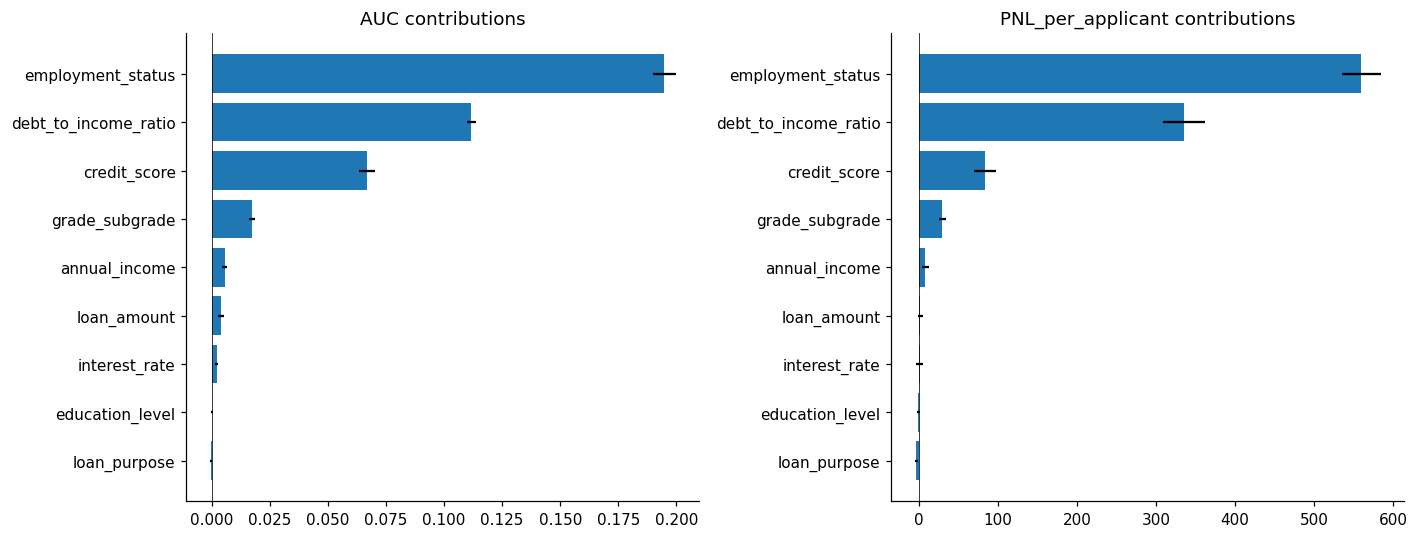

误差线仅为背景随机化的 Monte Carlo SE，不是客户总体抽样置信区间。


In [9]:
def xper_decompose(bundle,df,background,draws,seed):
    d=len(bundle["features"]);rng=np.random.default_rng(seed)
    donor_positions=rng.integers(0,len(background),size=(draws,len(df)))
    values=np.zeros((1<<d,draws,2))
    for mask in range(1<<d):
        if mask%64==0:print("XPER coalition",mask,"/",1<<d,flush=True)
        for r in range(draws):
            hybrid=df.copy()
            donors=background.iloc[donor_positions[r]]
            for j,c in enumerate(bundle["features"]):
                if not (mask>>j)&1:hybrid[c]=donors[c].to_numpy()
            p=predict(bundle,hybrid)
            values[mask,r]=[roc_auc_score(df[TARGET],p),profits(df,p>=bundle["threshold"]).mean()]
    phi=np.zeros((d,draws,2))
    for j in range(d):
        for mask in range(1<<d):
            if not (mask>>j)&1:
                weight=1/(d*comb(d-1,mask.bit_count()))
                phi[j]+=weight*(values[mask|(1<<j)]-values[mask])
    np.testing.assert_allclose(values[0]+phi.sum(axis=0),values[-1],rtol=1e-9,atol=1e-8)
    rows=[]
    for k,metric in enumerate(["AUC","PNL_per_applicant"]):
        for j,c in enumerate(bundle["features"]):
            rows.append({"Metric":metric,"Feature":c,"Contribution":phi[j,:,k].mean(),
                         "MC_SE":phi[j,:,k].std(ddof=1)/np.sqrt(draws)})
    summary=pd.DataFrame({"Metric":["AUC","PNL_per_applicant"],"Empty_baseline":values[0].mean(axis=0),
                          "Sum_contributions":phi.mean(axis=1).sum(axis=0),"Full_value":values[-1].mean(axis=0)})
    return pd.DataFrame(rows),summary

xper_sample,_=train_test_split(comparison,train_size=min(XPER_N,len(comparison)-1),
                              stratify=comparison[TARGET],random_state=SEED)
xper_values,xper_summary=xper_decompose(baseline,xper_sample,fit42,XPER_DRAWS,SEED)
table("xper_values",xper_values);table("xper_additivity",xper_summary)
fig,axes=plt.subplots(1,2,figsize=(13,5))
for ax,(metric,g) in zip(axes,xper_values.groupby("Metric",sort=False)):
    g=g.sort_values("Contribution");ax.barh(g.Feature,g.Contribution,xerr=g.MC_SE)
    ax.set_title(metric+" contributions");ax.axvline(0,c="black",lw=.5)
figure("xper_contributions")
print("误差线仅为背景随机化的 Monte Carlo SE，不是客户总体抽样置信区间。")

## 9. 解释稳定性、决定一致性与输入噪声
p.227（193）：在相同特征、相同样本上比较 ||phi(f1)-phi(f2)||_2。
SHAP 的基准/训练路径可能随模型变化；报告的是本原生 TreeSHAP 定义下的解释稳定性。
同时计算归一化重要性距离、排名相关、客户贡献距离、固定阈值/各自阈值的决定翻转率。

,Family,Seed_A,Seed_B,Importance_L2,Normalized_L2,Rank_Spearman,Mean_local_L2,Top3_overlap,Mean_abs_probability_change,Fixed_threshold_flip,Own_threshold_flip
0,baseline,1,10,0.070592,0.019481,0.983333,0.196666,1.0,0.013150,0.032,0.032
1,baseline,1,42,0.047464,0.012886,0.983333,0.183180,1.0,0.012874,0.031,0.031
2,baseline,1,100,0.046713,0.014552,0.983333,0.182018,1.0,0.013516,0.030,0.032
3,baseline,1,2026,0.034005,0.008589,1.000000,0.172622,1.0,0.012609,0.029,0.033
4,baseline,10,42,0.025870,0.007412,1.000000,0.167753,1.0,0.012033,0.025,0.025
5,baseline,10,100,0.097024,0.030375,1.000000,0.190148,1.0,0.011774,0.020,0.020
6,baseline,10,2026,0.064037,0.019712,0.983333,0.180873,1.0,0.012393,0.027,0.035
7,baseline,42,100,0.073912,0.023675,1.000000,0.184004,1.0,0.011962,0.029,0.029
8,baseline,42,2026,0.040400,0.012844,0.983333,0.167859,1.0,0.012579,0.028,0.032
9,baseline,100,2026,0.036304,0.011599,0.983333,0.160872,1.0,0.011824,0.031,0.033


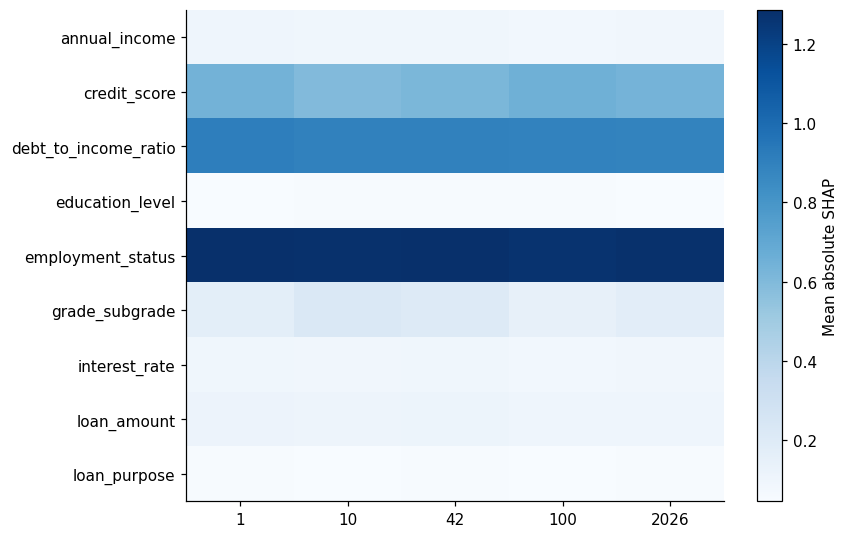

,Noise_SD_fraction,AUC_clean,AUC_noisy,Mean_abs_change,Decision_flip
0,0.05,0.911464,0.896004,0.028336,0.059


,Noise_SD_fraction,AUC_clean,AUC_noisy,Mean_abs_change,Decision_flip
0,0.05,0.911464,0.896004,0.028336,0.059


In [10]:
def stability_report(bundles,label):
    attrs={};preds={};global_rows=[]
    for s,b in bundles.items():
        vals,_=contributions(b,explain_df);attrs[s]=vals;preds[s]=predict(b,explain_df)
        for c,v in zip(FEATURES,np.abs(vals).mean(axis=0)):
            global_rows.append({"Family":label,"Seed":s,"Feature":c,"Mean_abs_SHAP":v})
    rows=[]
    for a,b in combinations(bundles,2):
        ga,gb=np.abs(attrs[a]).mean(axis=0),np.abs(attrs[b]).mean(axis=0)
        na,nb=ga/max(ga.sum(),1e-12),gb/max(gb.sum(),1e-12)
        rows.append({"Family":label,"Seed_A":a,"Seed_B":b,
            "Importance_L2":np.linalg.norm(ga-gb),"Normalized_L2":np.linalg.norm(na-nb),
            "Rank_Spearman":spearmanr(ga,gb).statistic,
            "Mean_local_L2":np.linalg.norm(attrs[a]-attrs[b],axis=1).mean(),
            "Top3_overlap":len(set(np.argsort(-ga)[:3])&set(np.argsort(-gb)[:3]))/3,
            "Mean_abs_probability_change":abs(preds[a]-preds[b]).mean(),
            "Fixed_threshold_flip":np.mean((preds[a]>=baseline["threshold"])!=(preds[b]>=baseline["threshold"])),
            "Own_threshold_flip":np.mean((preds[a]>=bundles[a]["threshold"])!=(preds[b]>=bundles[b]["threshold"]))})
    return pd.DataFrame(rows),pd.DataFrame(global_rows)

stability,importance_seeds=stability_report(models,"baseline")
table("explanation_stability",stability)
table("importance_by_seed",importance_seeds,False)
heat=importance_seeds.pivot(index="Feature",columns="Seed",values="Mean_abs_SHAP")
plt.figure(figsize=(8,5));plt.imshow(heat,aspect="auto",cmap="Blues")
plt.yticks(range(len(heat)),heat.index);plt.xticks(range(len(heat.columns)),heat.columns)
plt.colorbar(label="Mean absolute SHAP");figure("importance_stability_heatmap")
rng=np.random.default_rng(SEED);noisy=explain_df.copy()
for c in NUM:
    noisy[c]=np.clip(noisy[c]+rng.normal(0,.05*fit42[c].std(),len(noisy)),fit42[c].min(),fit42[c].max())
clean_p,noisy_p=predict(baseline,explain_df),predict(baseline,noisy)
table("input_noise",[{"Noise_SD_fraction":.05,"AUC_clean":roc_auc_score(explain_df[TARGET],clean_p),
    "AUC_noisy":roc_auc_score(explain_df[TARGET],noisy_p),"Mean_abs_change":abs(clean_p-noisy_p).mean(),
    "Decision_flip":np.mean((clean_p>=baseline["threshold"])!=(noisy_p>=baseline["threshold"]))}])

## 10. 训练时的稳定性约束：函数空间扩展实验
p.220、228（186、194）展示参数/特征贡献距离惩罚。树的结构变化使参数逐项比较不自然。
这里实现可微的**预测分数距离惩罚**：交叉熵 + lambda/2*(margin-anchor_margin)^2。
它体现“预测误差与稳定性权衡”，但不是精确复现课件的 SHAP 距离目标。
参考模型仅使用五个 fit 集的交集，并在交集内部再划分训练/早停/阈值样本。
不能直接拿种子42基准当参考：它可能已见过其他种子的 early-stop/threshold 标签。
下方逐种子断言参考数据与各自验证集无交集，comparison/audit/test 也不参与。
此实验预先固定 lambda；必须以共同样本实测是否降低解释距离，不能假定惩罚一定有效。

In [11]:
anchor_ids=set.intersection(*(set(splits[s][0][ID]) for s in SEEDS))
anchor_pool=core.loc[core[ID].isin(anchor_ids)].copy()
for s,(fit_s,es_s,thr_s) in splits.items():
    assert not anchor_ids & (set(es_s[ID])|set(thr_s[ID]))
for held_s in (comparison,audit,shared_test):
    assert not anchor_ids & set(held_s[ID])
anchor_fit,anchor_rest=train_test_split(anchor_pool,test_size=.30,stratify=anchor_pool[TARGET],random_state=SEED)
anchor_es,anchor_thr=train_test_split(anchor_rest,test_size=.50,stratify=anchor_rest[TARGET],random_state=SEED+1)
anchor_model=fit_bundle(SEED,training_frames=(anchor_fit,anchor_es,anchor_thr))
table("anchor_partition_sizes",[{"Partition":name,"Rows":len(df)} for name,df in
    [("anchor_fit",anchor_fit),("anchor_early_stop",anchor_es),("anchor_threshold",anchor_thr)]])
anchor_pool[[ID]].to_csv(OUT/"anchor_allowed_ids.csv",index=False)
stable_models={}
for seed in SEEDS:
    stable_models[seed]=fit_bundle(seed,anchor=anchor_model,strength=STABILITY_LAMBDA)
    print("稳定性约束模型完成",seed,flush=True)
stable_pairs,stable_importance=stability_report(stable_models,"anchor_penalty")
table("stability_constraint_pairs",stable_pairs)
table("stability_constraint_importance",stable_importance,False)
constraint_summary=pd.concat([stability,stable_pairs]).drop(columns=["Seed_A","Seed_B"]).groupby("Family").mean(numeric_only=True).reset_index()
table("stability_constraint_comparison",constraint_summary)
table("stability_constraint_performance",[dict(Seed=s,**metrics(comparison,predict(m,comparison),m["threshold"]))
                                         for s,m in stable_models.items()])

,Partition,Rows
0,anchor_fit,76468
1,anchor_early_stop,16386
2,anchor_threshold,16386


稳定性约束模型完成 1
稳定性约束模型完成 10
稳定性约束模型完成 42
稳定性约束模型完成 100
稳定性约束模型完成 2026


,Family,Seed_A,Seed_B,Importance_L2,Normalized_L2,Rank_Spearman,Mean_local_L2,Top3_overlap,Mean_abs_probability_change,Fixed_threshold_flip,Own_threshold_flip
0,anchor_penalty,1,10,0.055260,0.018359,1.000000,0.124044,1.0,0.009897,0.023,0.029
1,anchor_penalty,1,42,0.037098,0.012168,0.983333,0.111692,1.0,0.009757,0.019,0.019
2,anchor_penalty,1,100,0.020919,0.007600,0.983333,0.101348,1.0,0.009063,0.023,0.032
3,anchor_penalty,1,2026,0.011060,0.003901,1.000000,0.100551,1.0,0.009018,0.020,0.025
4,anchor_penalty,10,42,0.023256,0.007393,0.983333,0.103032,1.0,0.009164,0.020,0.030
5,anchor_penalty,10,100,0.073915,0.025056,0.983333,0.126712,1.0,0.008596,0.020,0.045
6,anchor_penalty,10,2026,0.060342,0.019910,1.000000,0.125562,1.0,0.009533,0.025,0.024
7,anchor_penalty,42,100,0.055755,0.019189,1.000000,0.119251,1.0,0.009034,0.024,0.033
8,anchor_penalty,42,2026,0.041913,0.013608,0.983333,0.113629,1.0,0.010101,0.023,0.028
9,anchor_penalty,100,2026,0.017984,0.007477,0.983333,0.104748,1.0,0.009512,0.017,0.033


,Family,Importance_L2,Normalized_L2,Rank_Spearman,Mean_local_L2,Top3_overlap,Mean_abs_probability_change,Fixed_threshold_flip,Own_threshold_flip
0,anchor_penalty,0.039750,0.013466,0.99,0.113057,1.0,0.009368,0.0214,0.0298
1,baseline,0.053632,0.016113,0.99,0.178600,1.0,0.012471,0.0282,0.0302


,Seed,N,AUC,AP_repaid,AP_default,Gini,KS,Brier,Accuracy,PNL,PNL_per_applicant,Approval,Default_among_approved,Threshold
0,1,57399,0.919654,0.974434,0.830040,0.839308,0.676854,0.072603,0.844039,5.180983e+07,902.625950,0.715483,0.050745,0.83
1,10,57399,0.919405,0.974301,0.830224,0.838810,0.676749,0.072521,0.858691,5.209987e+07,907.679045,0.737452,0.054195,0.81
2,42,57399,0.919916,0.974494,0.830503,0.839833,0.679157,0.072460,0.845084,5.192355e+07,904.607157,0.716668,0.050758,0.83
3,100,57399,0.919598,0.974371,0.830346,0.839196,0.677656,0.072550,0.834962,5.173591e+07,901.338108,0.701772,0.048435,0.84
4,2026,57399,0.919533,0.974355,0.830151,0.839066,0.677115,0.072560,0.852001,5.222509e+07,909.860686,0.726232,0.051913,0.82


,Seed,N,AUC,AP_repaid,AP_default,Gini,KS,Brier,Accuracy,PNL,PNL_per_applicant,Approval,Default_among_approved,Threshold
0,1,57399,0.919654,0.974434,0.830040,0.839308,0.676854,0.072603,0.844039,5.180983e+07,902.625950,0.715483,0.050745,0.83
1,10,57399,0.919405,0.974301,0.830224,0.838810,0.676749,0.072521,0.858691,5.209987e+07,907.679045,0.737452,0.054195,0.81
2,42,57399,0.919916,0.974494,0.830503,0.839833,0.679157,0.072460,0.845084,5.192355e+07,904.607157,0.716668,0.050758,0.83
3,100,57399,0.919598,0.974371,0.830346,0.839196,0.677656,0.072550,0.834962,5.173591e+07,901.338108,0.701772,0.048435,0.84
4,2026,57399,0.919533,0.974355,0.830151,0.839066,0.677115,0.072560,0.852001,5.222509e+07,909.860686,0.726232,0.051913,0.82


## 11. FPDP 与候选变量：差异可能由什么因素驱动
p.287、290–291（250、253–254）：固定某特征为同一值，重算公平统计量，其他输入及原群体
成员资格保持不变；若原检验拒绝，而网格上存在不拒绝的点，就标为探索性候选变量。
不拒绝不等于证明公平；网格搜索涉及多重尝试，不能把候选筛选当作正式因果检验。
排除“所有人都获批/被拒”的退化情况。全群体卡方检验遇到稀疏期望计数时标记不可评估。

,Feature,Attribute,Original_p,Grid_assessed,Candidate_exploratory,Max_grid_p
0,annual_income,education_level,0.010039,12,True,6.135336e-02
1,annual_income,employment_status,0.000000,12,False,0.000000e+00
2,annual_income,gender,0.350942,12,False,4.727409e-01
3,annual_income,marital_status,0.962532,12,False,9.909521e-01
4,credit_score,education_level,0.010039,12,True,1.726823e-01
5,credit_score,employment_status,0.000000,12,False,3.516157e-273
6,credit_score,gender,0.350942,11,False,5.322015e-01
7,credit_score,marital_status,0.962532,12,False,6.915513e-01
8,debt_to_income_ratio,education_level,0.010039,11,True,1.673319e-01
9,debt_to_income_ratio,employment_status,0.000000,11,False,4.770289e-127


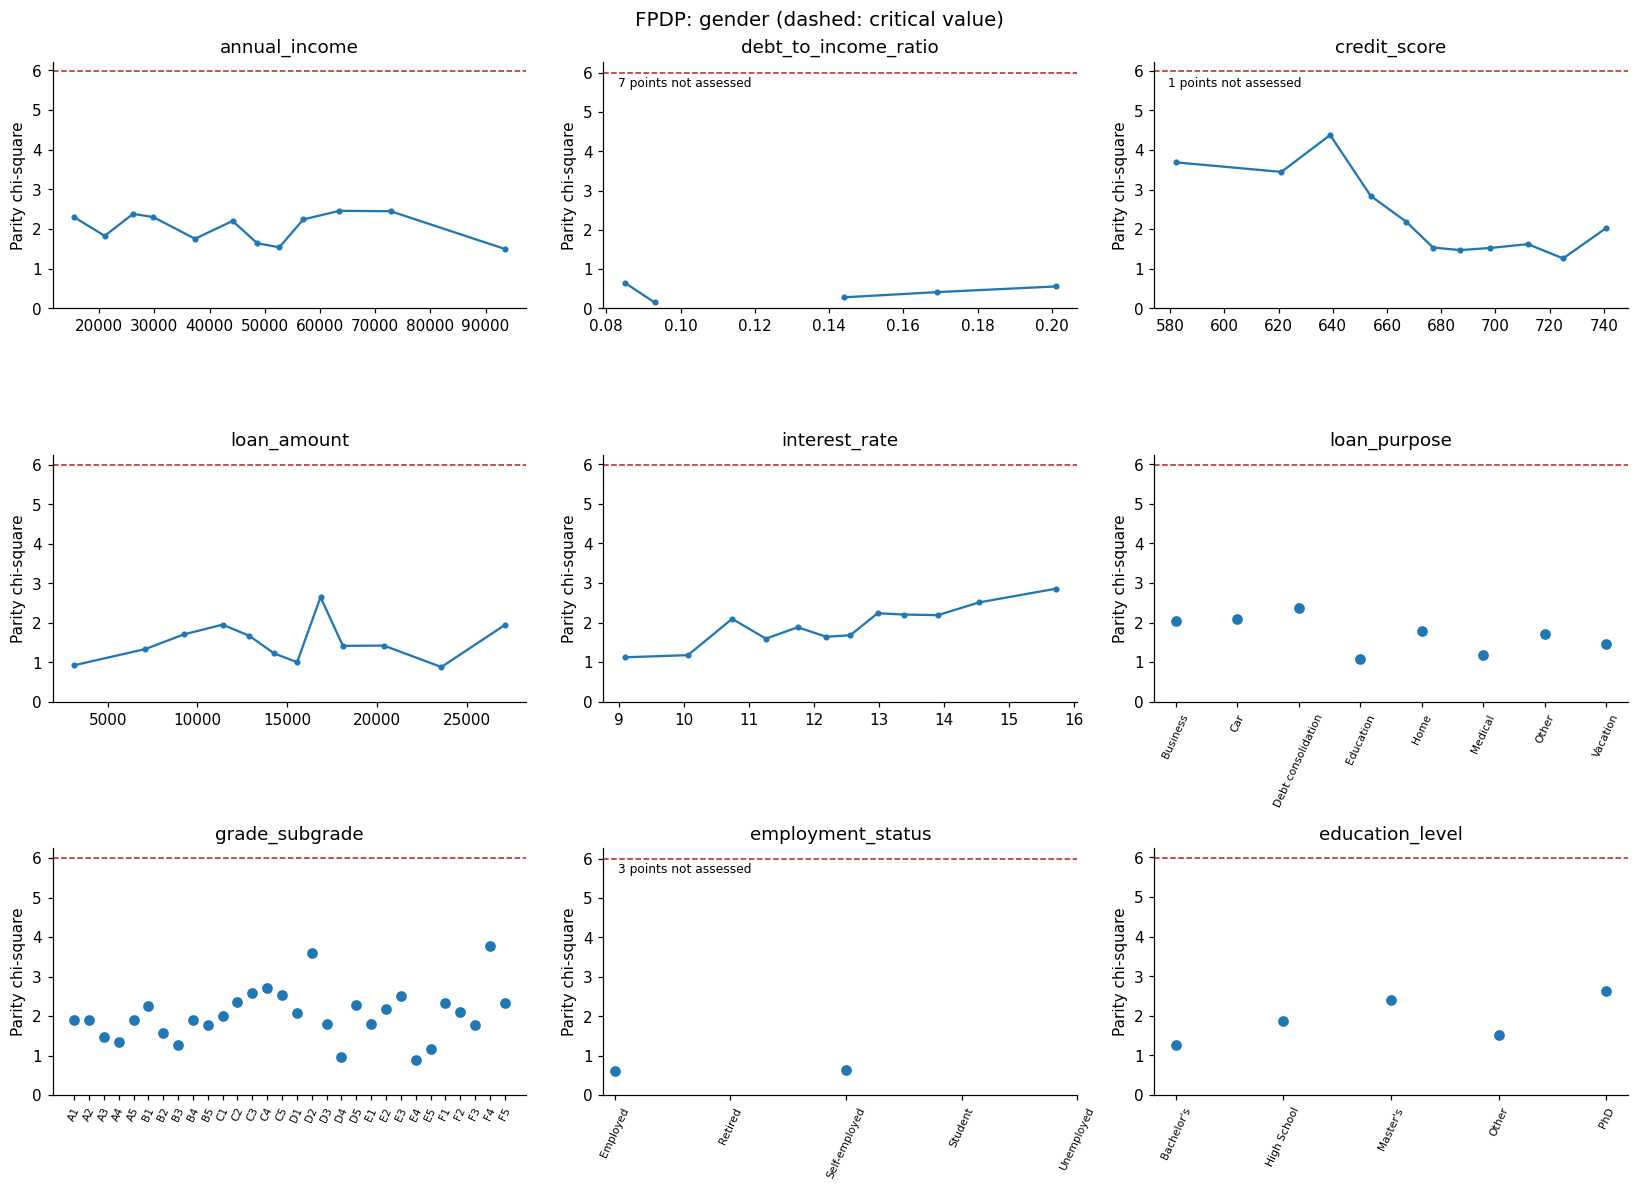

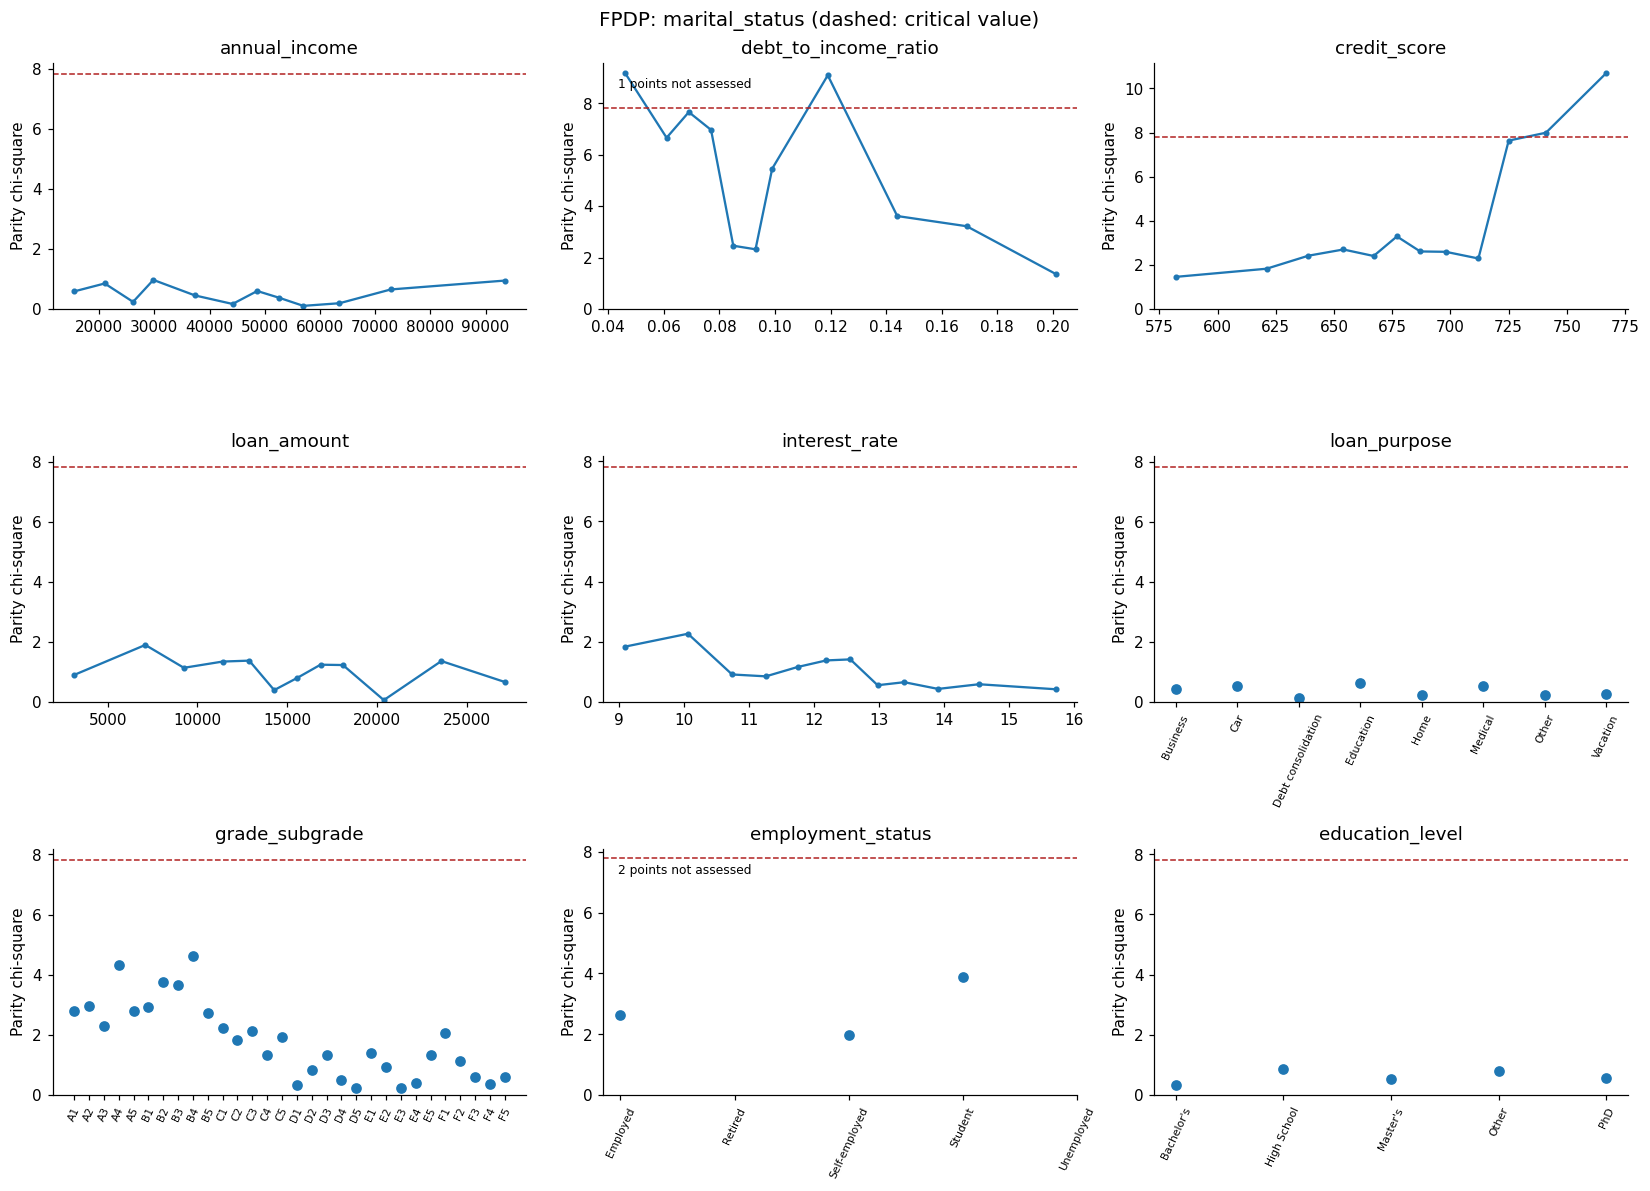

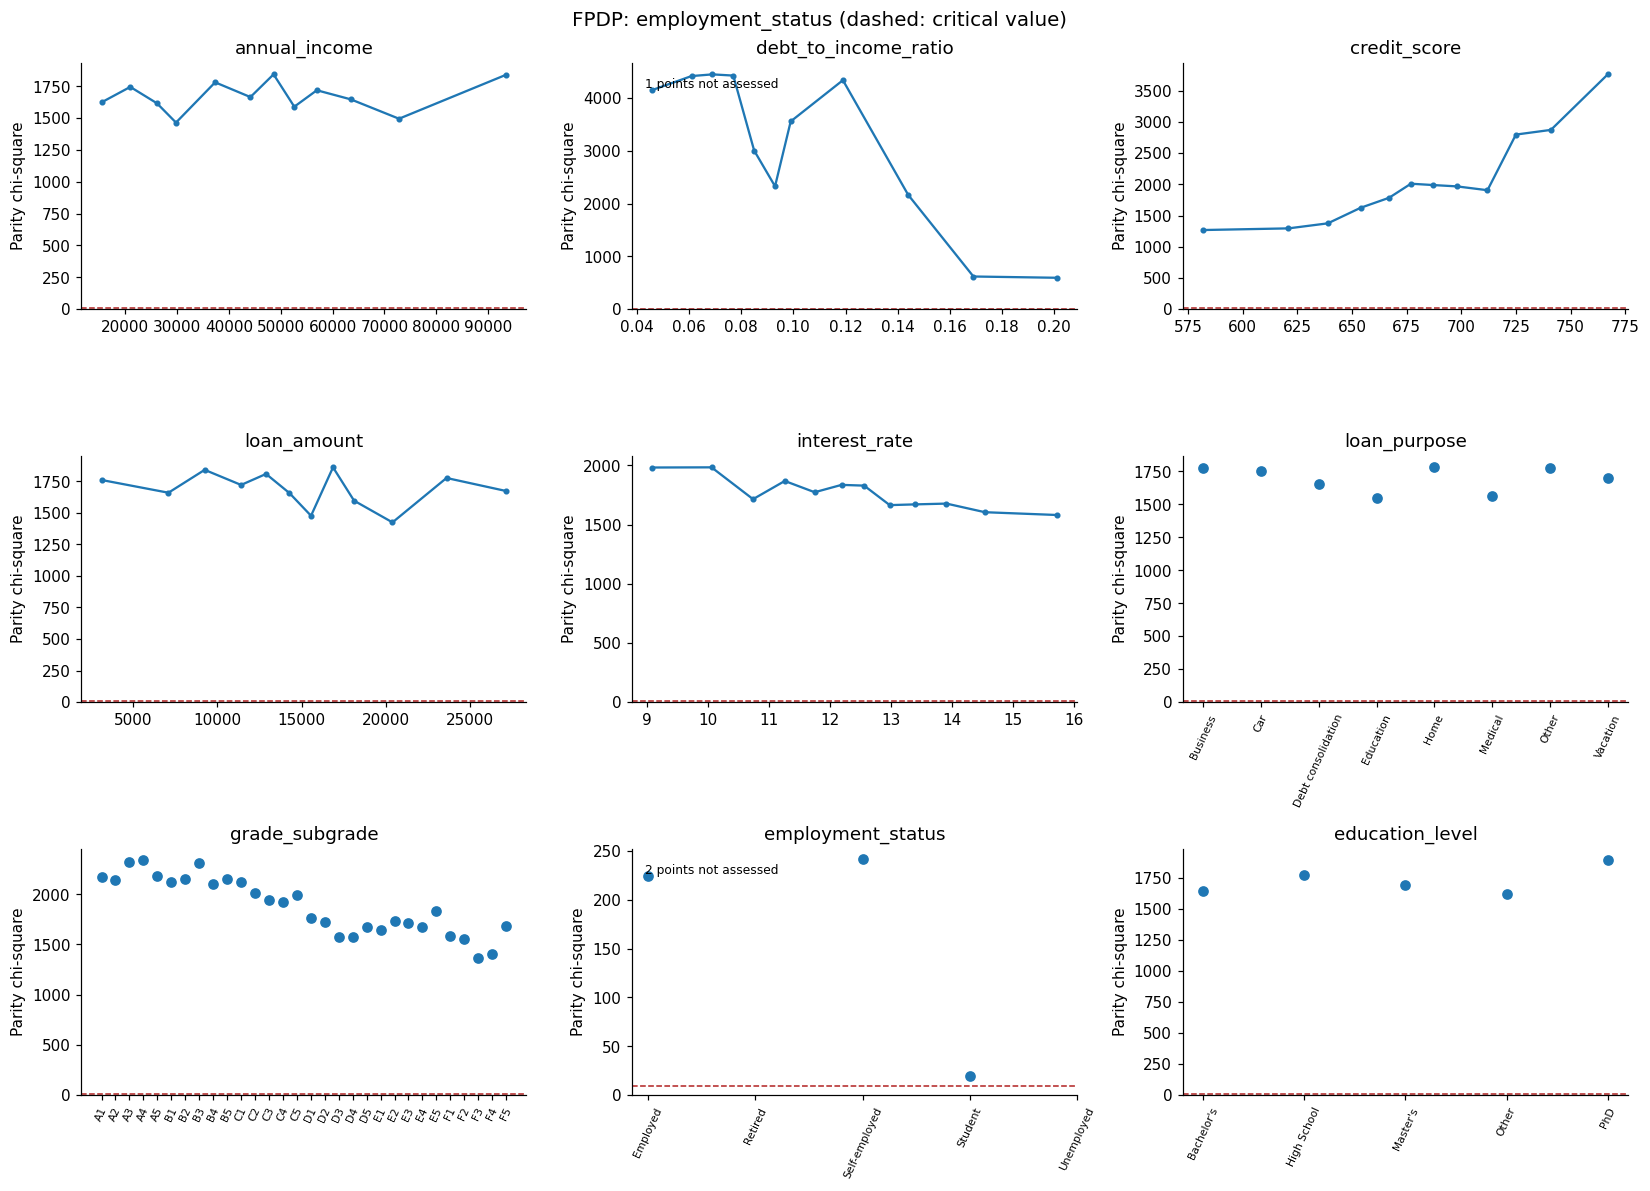

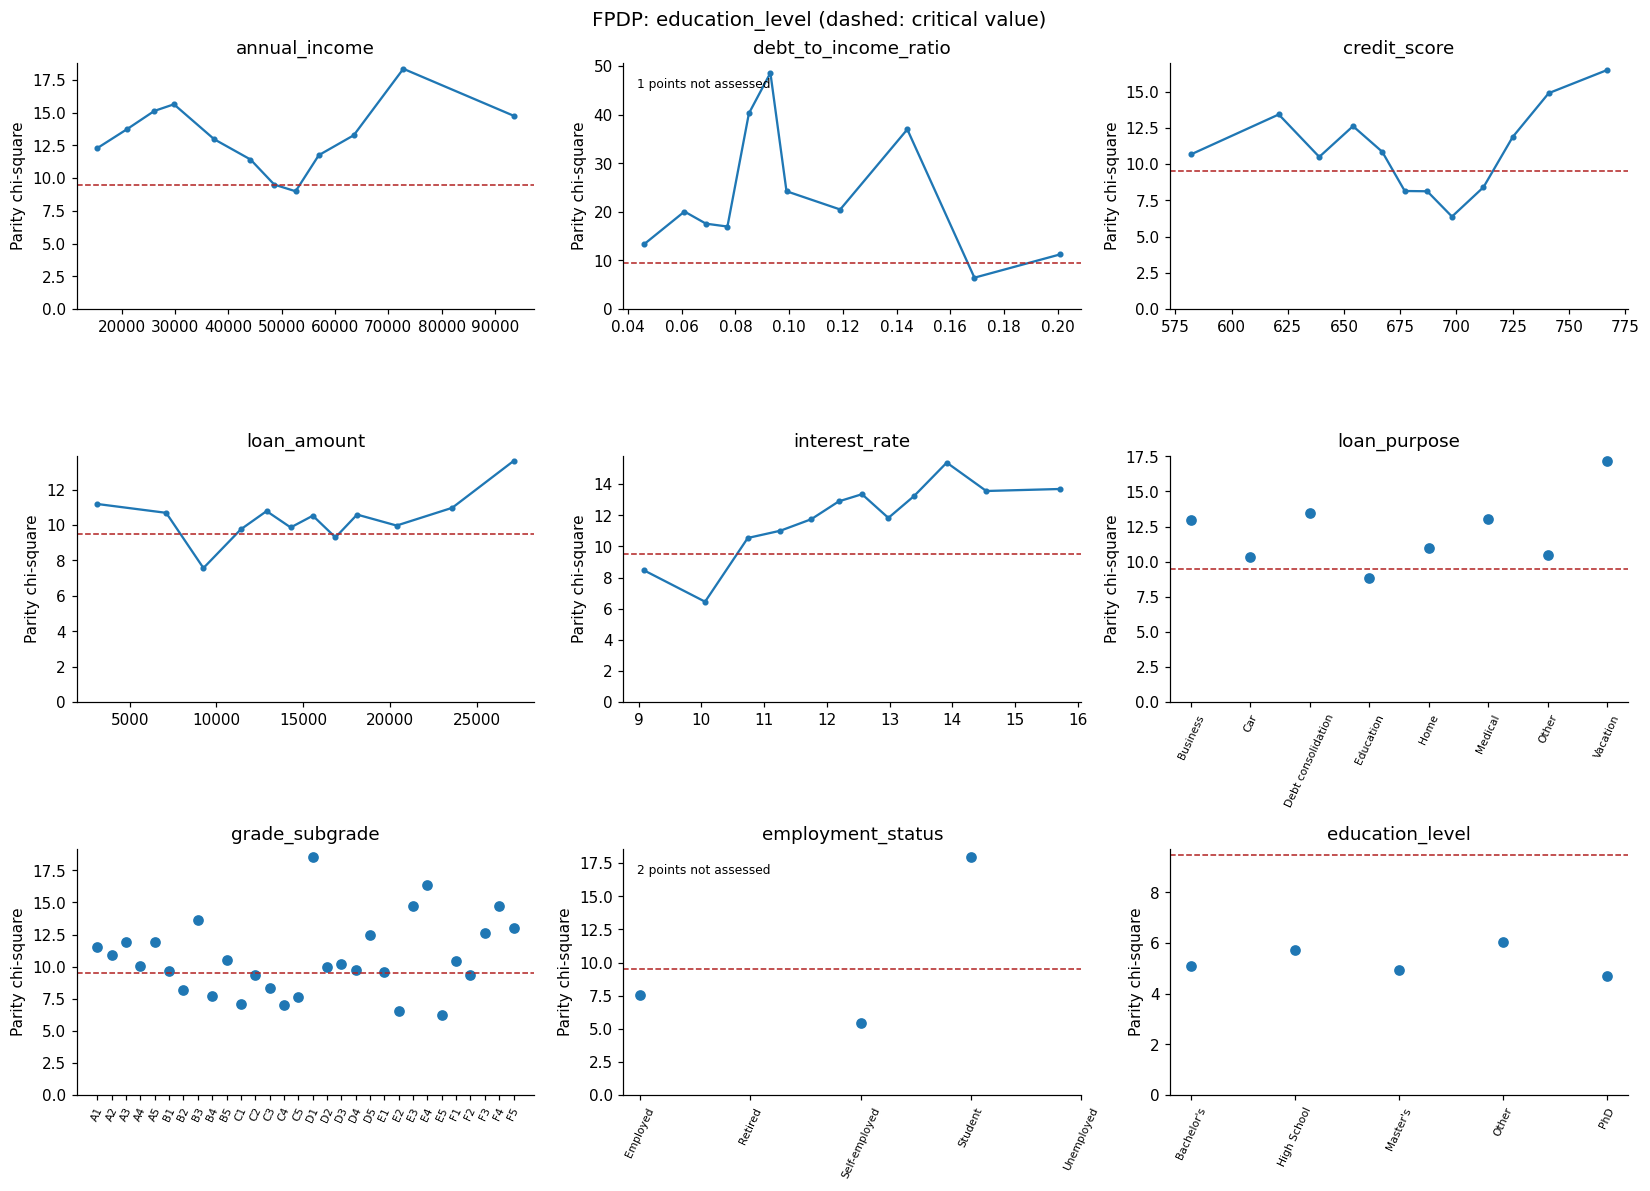

In [12]:
def independence_stat(group,decision):
    ct=pd.crosstab(np.asarray(group),np.asarray(decision)).reindex(columns=[False,True],fill_value=0)
    if ct.shape[0]<2 or (ct.sum(axis=0)==0).any():
        return {"Chi2":0.,"p":np.nan,"critical":np.nan,"valid":False}
    stat,pv,dof,expected=chi2_contingency(ct,correction=False)
    valid=bool(np.all(expected>=5))
    return {"Chi2":float(stat),"p":float(pv) if valid else np.nan,
            "critical":float(chi2.ppf(1-ALPHA,dof)),"valid":valid}

fpdp_df=comparison.sample(min(FPDP_N,len(comparison)),random_state=SEED)
base_dec=predict(baseline,fpdp_df)>=baseline["threshold"]
original_stats={a:independence_stat(fpdp_df[a],base_dec) for a in AUDIT}
fpdp_rows=[]
for c in FEATURES:
    for value in feature_grid(c):
        changed=fpdp_df.copy();changed[c]=value
        decision=predict(baseline,changed)>=baseline["threshold"]
        for attr in AUDIT:
            stat=independence_stat(fpdp_df[attr],decision)  # D 仍为原始群体，绝不能随替换值重写。
            rates=pd.DataFrame({"D":fpdp_df[attr].to_numpy(),"A":decision}).groupby("D").A.mean()
            fpdp_rows.append({"Feature":c,"Value":str(value),"Attribute":attr,
                "Approval":decision.mean(),"Approval_gap":rates.max()-rates.min(),**stat})
fpdp=pd.DataFrame(fpdp_rows);table("fpdp_grid",fpdp,False)
candidate_rows=[]
for (c,attr),g in fpdp.groupby(["Feature","Attribute"]):
    eligible=g[g.valid & g.Approval.between(.05,.95)]
    candidate_rows.append({"Feature":c,"Attribute":attr,"Original_p":original_stats[attr]["p"],
        "Grid_assessed":len(eligible),"Candidate_exploratory":bool(original_stats[attr]["p"]<ALPHA and
                    (eligible.p>=ALPHA).any()),"Max_grid_p":eligible.p.max()})
candidates=table("fpdp_candidates",candidate_rows)
# 每个特征保留自身数值/类别坐标；稀疏或退化点不能画成“统计量为零、已经公平”。
for attr in AUDIT:
    fig,axes=plt.subplots(3,3,figsize=(15,11))
    for c,ax in zip(FEATURES,axes.ravel()):
        g=fpdp[(fpdp.Attribute==attr)&(fpdp.Feature==c)]
        valid=g.valid & g.Approval.between(.05,.95)
        ys=np.where(valid,g.Chi2,np.nan)
        if c in CAT:
            xs=np.arange(len(g));ax.scatter(xs,ys)
            ax.set_xticks(xs,g.Value,rotation=65,fontsize=7)
        else:
            xs=g.Value.astype(float).to_numpy();ax.plot(xs,ys,"o-",ms=3)
        if np.isfinite(original_stats[attr]["critical"]):
            ax.axhline(original_stats[attr]["critical"],ls="--",c="firebrick",lw=1)
        if not valid.all():
            ax.text(.03,.94,f"{int((~valid).sum())} points not assessed",transform=ax.transAxes,
                    va="top",fontsize=8)
        ax.set_title(c);ax.set_ylabel("Parity chi-square");ax.set_ylim(bottom=0)
    fig.suptitle("FPDP: "+attr+" (dashed: critical value)",fontsize=13)
    figure("fpdp_"+attr)

## 12. 特征与群体/标签的关联图
p.296–297（259–260）：同时看 X-D 和 X-Y，而非只看与敏感属性的关系。
类别特征用 Cramér's V；数值特征用 eta-squared。两种统计量定义不同，分图展示。
自关联是直接输入，不叫代理；相关性与 FPDP 都不是因果识别。

,Feature,Attribute,Measure,X_D,X_Y,Candidate_exploratory
0,annual_income,gender,Eta_squared,0.000019,0.000049,False
1,debt_to_income_ratio,gender,Eta_squared,0.000016,0.112637,False
2,credit_score,gender,Eta_squared,0.000055,0.054903,False
3,loan_amount,gender,Eta_squared,0.000008,0.000024,False
4,interest_rate,gender,Eta_squared,0.000018,0.017507,False
5,loan_purpose,gender,Cramers_V,0.008699,0.026559,False
6,grade_subgrade,gender,Cramers_V,0.011742,0.228022,False
7,employment_status,gender,Cramers_V,0.004216,0.658249,False
8,education_level,gender,Cramers_V,0.006208,0.025721,False
9,annual_income,marital_status,Eta_squared,0.000097,0.000049,False


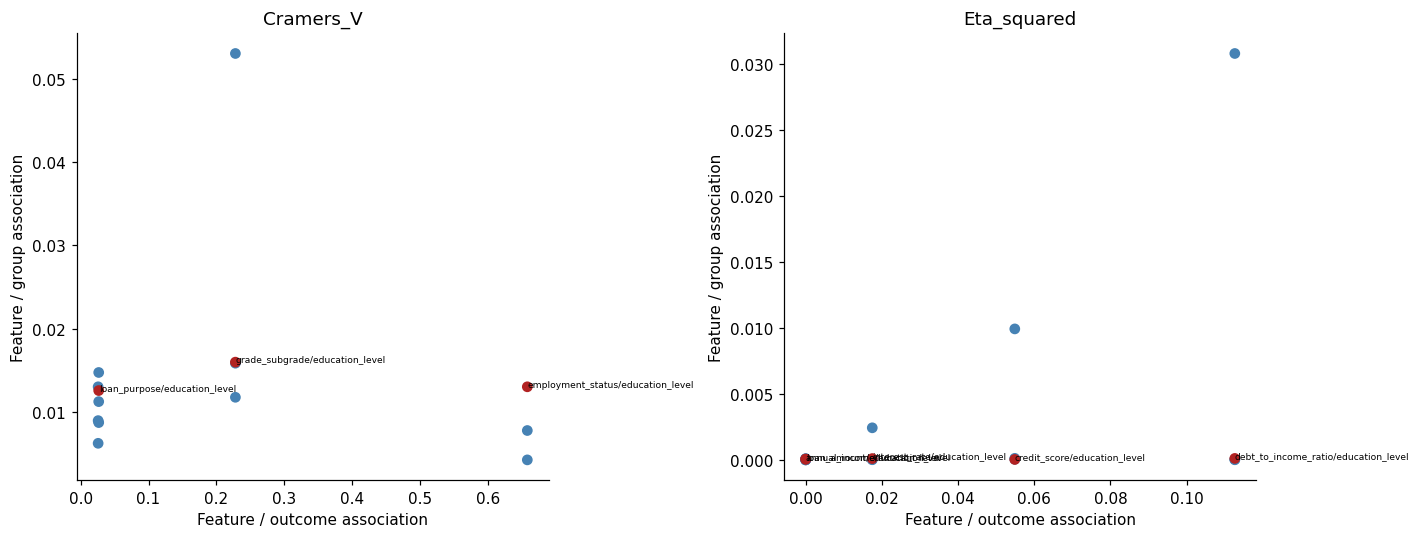

In [13]:
def association(feature,group,is_category):
    if is_category:
        ct=pd.crosstab(feature,group)
        if min(ct.shape)<2:return np.nan
        stat=chi2_contingency(ct,correction=False)[0]
        return np.sqrt(stat/(ct.to_numpy().sum()*(min(ct.shape)-1)))
    data=pd.DataFrame({"x":np.asarray(feature,float),"g":np.asarray(group)})
    ss=((data.x-data.x.mean())**2).sum()
    return sum(len(g)*(g.x.mean()-data.x.mean())**2 for _,g in data.groupby("g"))/ss if ss else np.nan

assoc=[]
for attr in AUDIT:
    for c in FEATURES:
        if c==attr:continue
        flag=c in CAT
        assoc.append({"Feature":c,"Attribute":attr,"Measure":"Cramers_V" if flag else "Eta_squared",
            "X_D":association(fit42[c],fit42[attr],flag),"X_Y":association(fit42[c],fit42[TARGET],flag)})
assoc=pd.DataFrame(assoc).merge(candidates[["Feature","Attribute","Candidate_exploratory"]],how="left")
table("candidate_associations",assoc)
fig,axes=plt.subplots(1,2,figsize=(13,5))
for ax,(measure,g) in zip(axes,assoc.groupby("Measure")):
    ax.scatter(g.X_Y,g.X_D,c=np.where(g.Candidate_exploratory,"firebrick","steelblue"))
    for r in g.itertuples():
        if r.Candidate_exploratory:ax.annotate(r.Feature+"/"+r.Attribute,(r.X_Y,r.X_D),fontsize=6)
    ax.set_title(measure);ax.set_xlabel("Feature / outcome association");ax.set_ylabel("Feature / group association")
figure("candidate_associations")

## 13. 条件统计平等与分箱 Sufficiency
p.277（241）：控制非敏感 X_c 后检查批准与群体的关系。这里用训练集信用分、收入的
三分位数组合成层，以 CMH 检验两群体在层内批准率的关系。只支持所选控制和重叠区域。
p.278（242）：Sufficiency 为 Y 与 D 在给定分数后独立；这里按预先固定概率区间分层，
检验层内还款率差异，并输出各群体校准误差。**粗分箱诊断不是连续分数的完整证明。**
同一次审计的所有群体对/两类条件检验统一 Holm 校正；无共同支持或稀疏层不下结论。
CMH 聚合层内关联；方向相反的层效应可能抵消，因此还需结合分组校准表，不拒绝不能证明独立。

In [14]:
control_edges={c:np.r_[-np.inf,np.unique(np.quantile(fit42[c],[1/3,2/3])),np.inf]
               for c in ["credit_score","annual_income"]}
SCORE_EDGES=np.linspace(0,1,6)
def cmh_two_groups(group,outcome,strata,a,b):
    z=pd.DataFrame({"g":group,"y":np.asarray(outcome,int),"s":np.asarray(strata)})
    z=z[z.g.isin([a,b])];delta=variance=0.;covered=layers=0
    for _,g in z.groupby("s",observed=True):
        n1=(g.g==a).sum();n0=(g.g==b).sum();n=len(g);k=g.y.sum()
        if min(n1,n0)<5 or min(k,n-k)<5:continue
        observed=g.loc[g.g==a,"y"].sum();delta+=observed-n1*k/n
        variance+=n1*n0*k*(n-k)/(n*n*(n-1));covered+=n;layers+=1
    statistic=delta**2/variance if variance>0 else np.nan
    return {"CMH_chi2":statistic,"p_raw":chi2.sf(statistic,1),"Covered_N":covered,
            "Pair_N":len(z),"Coverage":covered/len(z) if len(z) else 0,"Layers":layers}

def conditional_audit(df,p,t):
    bins=[pd.cut(df[c],edges,labels=False).to_numpy() for c,edges in control_edges.items()]
    controls=np.array([f"{a}_{b}" for a,b in zip(*bins)])
    score_bins=pd.cut(np.asarray(p),SCORE_EDGES,labels=False,include_lowest=True)
    rows=[];calibration=[]
    for attr in AUDIT:
        for a,b in combinations(sorted(df[attr].unique()),2):
            for label,outcome,strata in [("Conditional_statistical_parity",np.asarray(p)>=t,controls),
                                        ("Binned_sufficiency",df[TARGET],score_bins)]:
                rows.append({"Attribute":attr,"Group_A":a,"Group_B":b,"Test":label,
                             **cmh_two_groups(df[attr].to_numpy(),outcome,strata,a,b)})
        temp=pd.DataFrame({"g":df[attr].to_numpy(),"bin":score_bins,"p":p,"y":df[TARGET].to_numpy()})
        for (g,b),v in temp.groupby(["g","bin"],observed=True):
            calibration.append({"Attribute":attr,"Group":g,"Score_bin":b,"N":len(v),
                "Mean_p":v.p.mean(),"Observed_repaid":v.y.mean(),"Calibration_gap":v.y.mean()-v.p.mean()})
    tests=pd.DataFrame(rows);tests["p_Holm"]=holm(tests.p_raw)
    tests["Interpretation"]=np.where(tests.p_raw.isna(),"not assessed",
        np.where(tests.p_Holm<ALPHA,"conditional association detected","not rejected; not proof of fairness"))
    return tests,pd.DataFrame(calibration)

conditional_comp,calibration_comp=conditional_audit(comparison,p_comp,baseline["threshold"])
table("conditional_fairness_comparison",conditional_comp)
table("group_calibration_comparison",calibration_comp,False)

,Attribute,Group_A,Group_B,Test,CMH_chi2,p_raw,Covered_N,Pair_N,Coverage,Layers,p_Holm,Interpretation
0,gender,Female,Male,Conditional_statistical_parity,1.044996,3.066625e-01,57025,57025,1.000000,9,1.000000e+00,not rejected; not proof of fairness
1,gender,Female,Male,Binned_sufficiency,2.400585,1.212899e-01,57025,57025,1.000000,5,1.000000e+00,not rejected; not proof of fairness
2,gender,Female,Other,Conditional_statistical_parity,0.979519,3.223175e-01,29803,29803,1.000000,9,1.000000e+00,not rejected; not proof of fairness
3,gender,Female,Other,Binned_sufficiency,0.044628,8.326891e-01,29279,29803,0.982418,4,1.000000e+00,not rejected; not proof of fairness
4,gender,Male,Other,Conditional_statistical_parity,1.338179,2.473554e-01,27970,27970,1.000000,9,1.000000e+00,not rejected; not proof of fairness
5,gender,Male,Other,Binned_sufficiency,0.274342,6.004336e-01,27449,27970,0.981373,4,1.000000e+00,not rejected; not proof of fairness
6,marital_status,Divorced,Married,Conditional_statistical_parity,0.335068,5.626900e-01,28792,28792,1.000000,9,1.000000e+00,not rejected; not proof of fairness
7,marital_status,Divorced,Married,Binned_sufficiency,0.258251,6.113244e-01,28792,28792,1.000000,5,1.000000e+00,not rejected; not proof of fairness
8,marital_status,Divorced,Single,Conditional_statistical_parity,0.822180,3.645434e-01,30030,30030,1.000000,9,1.000000e+00,not rejected; not proof of fairness
9,marital_status,Divorced,Single,Binned_sufficiency,0.487478,4.850544e-01,30030,30030,1.000000,5,1.000000e+00,not rejected; not proof of fairness


,Attribute,Group,Score_bin,N,Mean_p,Observed_repaid,Calibration_gap
0,gender,Female,0,3005,0.031190,0.035607,0.004417
1,gender,Female,1,520,0.313761,0.290385,-0.023376
2,gender,Female,2,1313,0.510553,0.516375,0.005822
3,gender,Female,3,2606,0.716823,0.723715,0.006891
4,gender,Female,4,21985,0.944237,0.946827,0.002590
...,...,...,...,...,...,...,...
75,education_level,PhD,0,96,0.033355,0.041667,0.008311
76,education_level,PhD,1,20,0.304530,0.100000,-0.204530
77,education_level,PhD,2,39,0.517294,0.487179,-0.030114
78,education_level,PhD,3,91,0.716699,0.725275,0.008576


## 14. 公平性缓解实验与预先定义的选择规则
p.271、298–299（235、261–262）：比较公平性改善与预测/经济代价。
在相同 fit/es/threshold/comparison 行上比较：原9特征、去就业、去教育、同时去两者、
训练样本按 gender×Y 重加权，以及前述稳定性约束。敏感变量不作为群体专属审批阈值。
重加权权重=P(D)P(Y)/P(D,Y)，只由 fit 计算；不保证改善所有群体或所有公平指标。

选择准则预先固定：AUC 降幅不超过0.01、正收益降幅不超过5%，四个属性的最大批准率差距
比基准小，且最大 EO 差距不增加；符合者按最大批准率差距最小排序，否则保留基准。
这是课堂演示的政策假设，不是通用公平定义。全部选择只使用 comparison。

缓解候选完成 without_employment
缓解候选完成 without_education
缓解候选完成 without_both


,Variant,N,AUC,AP_repaid,AP_default,Gini,KS,Brier,Accuracy,PNL,PNL_per_applicant,Approval,Default_among_approved,Threshold,Worst_DP_gap,Worst_EO_gap,Eligible
0,baseline,57399,0.920415,0.974668,0.831120,0.840830,0.679955,0.072361,0.845729,5.210608e+07,907.787168,0.717033,0.050538,0.83,0.990445,0.999460,False
1,stability_penalty,57399,0.919916,0.974494,0.830503,0.839833,0.679157,0.072460,0.845084,5.192355e+07,904.607157,0.716668,0.050758,0.83,0.993410,0.999640,False
2,without_employment,57399,0.806078,0.937665,0.535437,0.612155,0.457149,0.125003,0.708636,3.133348e+07,545.888981,0.604923,0.080554,0.81,0.356853,0.213139,False
3,without_education,57399,0.920458,0.974659,0.831150,0.840917,0.679861,0.072371,0.852889,5.244191e+07,913.638017,0.726528,0.051484,0.82,0.989456,0.999460,True
4,without_both,57399,0.805839,0.937584,0.534907,0.611678,0.455981,0.125051,0.721964,3.108445e+07,541.550297,0.626405,0.084300,0.80,0.352465,0.206361,False
5,gender_reweight,57399,0.920436,0.974687,0.831133,0.840872,0.679651,0.072321,0.845868,5.219317e+07,909.304599,0.716824,0.050310,0.83,0.990445,0.999460,False


冻结方案: without_education | 冻结阈值: 0.8200000000000001


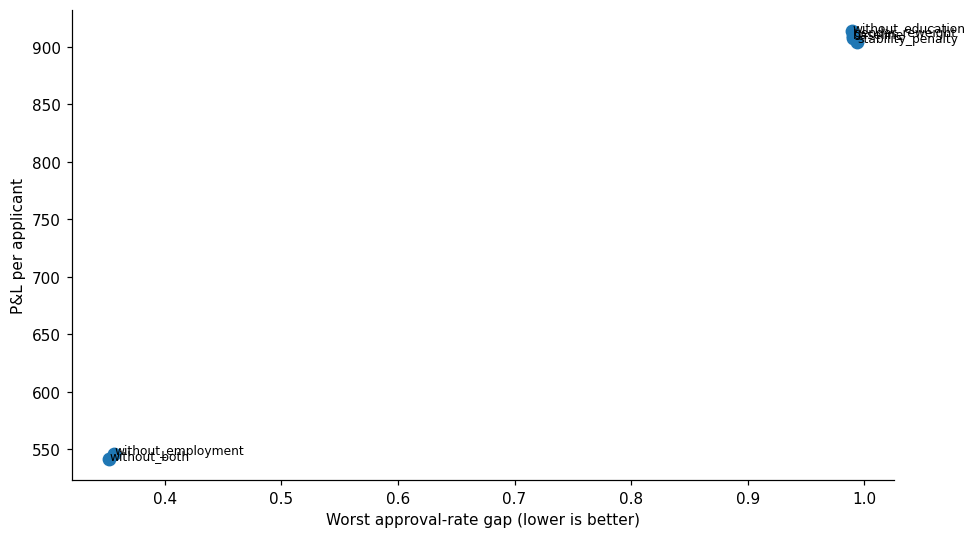

In [15]:
variants={"baseline":baseline,"stability_penalty":stable_models[SEED]}
for name,features in [("without_employment",[c for c in FEATURES if c!="employment_status"]),
                       ("without_education",[c for c in FEATURES if c!="education_level"]),
                       ("without_both",BASE)]:
    variants[name]=fit_bundle(SEED,features)
    print("缓解候选完成",name,flush=True)
counts=fit42.groupby(["gender",TARGET]).size();gd=fit42.gender.value_counts(normalize=True)
yd=fit42[TARGET].value_counts(normalize=True)
weights=np.array([gd[g]*yd[y]/(counts.loc[(g,y)]/len(fit42)) for g,y in zip(fit42.gender,fit42[TARGET])])
weights/=weights.mean()
variants["gender_reweight"]=fit_bundle(SEED,weight=weights)
tradeoffs=[]
for name,bundle in variants.items():
    p=predict(bundle,comparison);detail=group_metrics(comparison,p,bundle["threshold"]);g=gaps(detail)
    tradeoffs.append({"Variant":name,**metrics(comparison,p,bundle["threshold"]),
                      "Worst_DP_gap":g.Approval_gap.max(),"Worst_EO_gap":g.EO_gap.max()})
    table("mitigation_"+name+"_groups",detail,False)
tradeoffs=pd.DataFrame(tradeoffs);base_row=tradeoffs.set_index("Variant").loc["baseline"]
tradeoffs["Eligible"]=(tradeoffs.AUC>=base_row.AUC-MAX_AUC_LOSS)&(
    tradeoffs.PNL>=base_row.PNL-MAX_PNL_LOSS*abs(base_row.PNL))&(
    tradeoffs.Worst_DP_gap<base_row.Worst_DP_gap-1e-6)&(
    tradeoffs.Worst_EO_gap<=base_row.Worst_EO_gap+1e-6)
eligible=tradeoffs[tradeoffs.Eligible].sort_values(["Worst_DP_gap","PNL"],ascending=[True,False])
SELECTED_NAME=str(eligible.iloc[0].Variant) if len(eligible) else "baseline"
selected=variants[SELECTED_NAME]
table("mitigation_tradeoffs",tradeoffs)
print("冻结方案:",SELECTED_NAME,"| 冻结阈值:",selected["threshold"])
fig,ax=plt.subplots(figsize=(9,5))
ax.scatter(tradeoffs.Worst_DP_gap,tradeoffs.PNL_per_applicant,s=65)
for r in tradeoffs.itertuples():ax.annotate(r.Variant,(r.Worst_DP_gap,r.PNL_per_applicant),fontsize=8)
ax.set_xlabel("Worst approval-rate gap (lower is better)");ax.set_ylabel("P&L per applicant")
figure("mitigation_tradeoff")

## 15. 冻结之后的独立审计与共享测试报告
此处才对 audit/test 计算最终结果；不据其结果再改特征、种子、阈值或选择规则。
同时报告预先固定的基准与已冻结方案；若相同只报告一次。
置信区间通过客户行重采样计算，是固定已训练模型的评价不确定性，不包含重新训练不确定性。
两模型差异使用同一组重采样索引（paired bootstrap），避免独立抽样扩大噪声。

,Dataset,Variant,N,AUC,AP_repaid,AP_default,Gini,KS,Brier,Accuracy,PNL,PNL_per_applicant,Approval,Default_among_approved,Threshold
0,independent_audit,baseline,57400,0.923826,0.975797,0.838859,0.847651,0.686690,0.070532,0.850662,5.251031e+07,914.813685,0.719965,0.048952,0.83
1,independent_audit,without_education,57400,0.924011,0.975876,0.838944,0.848023,0.686681,0.070502,0.856742,5.245893e+07,913.918582,0.729913,0.050934,0.82
2,shared_test_20k,baseline,20000,0.917184,0.973360,0.826364,0.834369,0.671602,0.073876,0.846450,1.765688e+07,882.844221,0.720750,0.052376,0.83
3,shared_test_20k,without_education,20000,0.917126,0.973357,0.826385,0.834252,0.671457,0.073857,0.853050,1.772296e+07,886.148016,0.730050,0.053558,0.82


,Variant,Metric,CI_low,CI_high
0,baseline,AUC,0.911927,0.921502
1,baseline,PNL_per_applicant,850.236070,914.207037
2,without_education,AUC,0.911958,0.921232
3,without_education,PNL_per_applicant,849.139841,916.867932
4,without_education minus baseline (paired),AUC,-0.000504,0.000395
5,without_education minus baseline (paired),PNL_per_applicant,-5.793829,11.912622


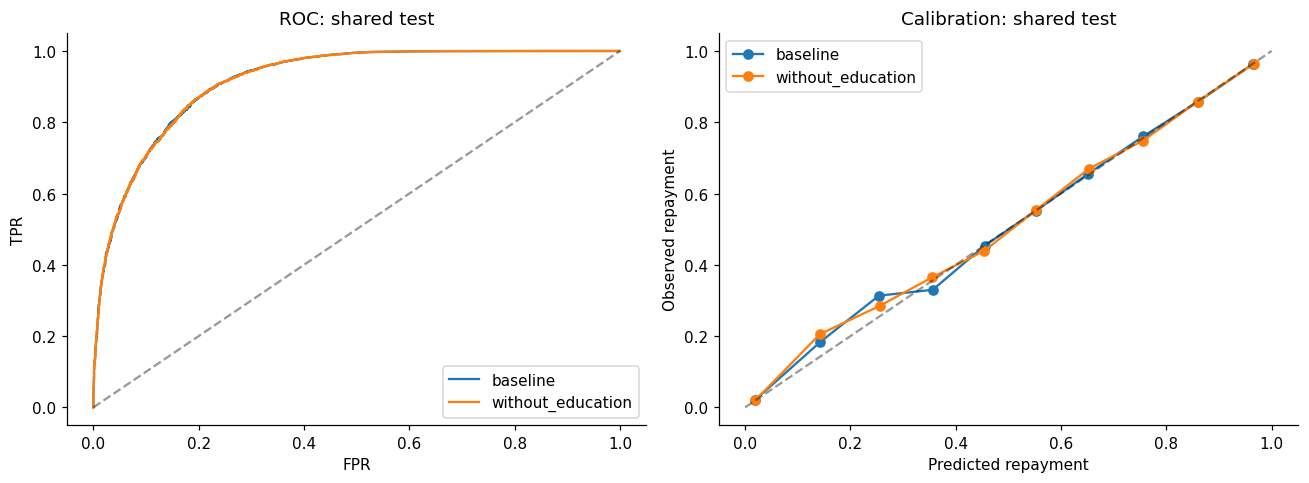

In [16]:
report_models={"baseline":baseline}
if SELECTED_NAME!="baseline":report_models[SELECTED_NAME]=selected
final_rows=[];predictions={}
for dataset,df in [("independent_audit",audit),("shared_test_20k",shared_test)]:
    for name,bundle in report_models.items():
        p=predict(bundle,df);predictions[(dataset,name)]=p
        final_rows.append({"Dataset":dataset,"Variant":name,**metrics(df,p,bundle["threshold"])})
        detail=group_metrics(df,p,bundle["threshold"])
        table(f"{dataset}_{name}_groups",detail,False)
        table(f"{dataset}_{name}_gaps",gaps(detail),False)
        table(f"{dataset}_{name}_tost",equivalence_tests(detail),False)
        conditional,cal=conditional_audit(df,p,bundle["threshold"])
        table(f"{dataset}_{name}_conditional",conditional,False)
        table(f"{dataset}_{name}_calibration",cal,False)
        table(f"{dataset}_{name}_predictions",pd.DataFrame({ID:df[ID].to_numpy(),"Actual":df[TARGET].to_numpy(),
            "P_repaid":p,"Threshold":bundle["threshold"],"Approve":p>=bundle["threshold"]}),False)
final_metrics=table("final_metrics",final_rows)

def bootstrap_comparison(df,model_dict,probs):
    rng=np.random.default_rng(SEED);store={name:[] for name in model_dict}
    for _ in range(BOOTSTRAP_B):
        ix=rng.integers(0,len(df),len(df));part=df.iloc[ix]
        if part[TARGET].nunique()<2:continue
        for name,b in model_dict.items():
            p=probs[name][ix]
            store[name].append([roc_auc_score(part[TARGET],p),profits(part,p>=b["threshold"]).mean()])
    rows=[]
    for name,vals in store.items():
        for j,metric in enumerate(["AUC","PNL_per_applicant"]):
            lo,hi=np.quantile(np.asarray(vals)[:,j],[.025,.975])
            rows.append({"Variant":name,"Metric":metric,"CI_low":lo,"CI_high":hi})
    if len(store)==2:
        other=next(n for n in store if n!="baseline")
        delta=np.asarray(store[other])-np.asarray(store["baseline"])
        for j,metric in enumerate(["AUC","PNL_per_applicant"]):
            lo,hi=np.quantile(delta[:,j],[.025,.975])
            rows.append({"Variant":other+" minus baseline (paired)","Metric":metric,"CI_low":lo,"CI_high":hi})
    return pd.DataFrame(rows)

table("shared_test_confidence_intervals",bootstrap_comparison(shared_test,report_models,
    {n:predictions[("shared_test_20k",n)] for n in report_models}))
fig,axes=plt.subplots(1,2,figsize=(12,4.5))
for name,b in report_models.items():
    p=predictions[("shared_test_20k",name)]
    fpr,tpr,_=roc_curve(shared_test[TARGET],p);axes[0].plot(fpr,tpr,label=name)
    bins=pd.cut(p,np.linspace(0,1,11),include_lowest=True)
    cal=pd.DataFrame({"bin":bins,"p":p,"y":shared_test[TARGET].to_numpy()}).groupby("bin",observed=True).agg(
        Mean_p=("p","mean"),Observed=("y","mean"),N=("y","size")).reset_index()
    table("calibration_curve_"+name,cal,False)
    axes[1].plot(cal.Mean_p,cal.Observed,"o-",label=name)
for ax in axes:ax.plot([0,1],[0,1],"k--",alpha=.4);ax.legend()
axes[0].set(xlabel="FPR",ylabel="TPR",title="ROC: shared test")
axes[1].set(xlabel="Predicted repayment",ylabel="Observed repayment",title="Calibration: shared test")
figure("final_roc_calibration")

## 16. 四维取舍、解释与交付
下方自动生成的是本次运行的事实摘要，不预填旧 AUC 或收益。
仅覆盖 XGBoost 内部方案；三模型的客户部署建议仍需纳入另外两位队友的同口径结果。
公平与稳定的结论限定于此数据、阈值、分组和实验设定，不能扩展成法律认证或因果结论。

In [17]:
print("===== 本次运行四维摘要 =====")
print("模式:",MODE,"；正式提交必须使用 full 的完整输出。")
print("预测与收益：请读 final_metrics 和配对置信区间；AP 同时导出还款/违约两种正类。")
top_features=importance.sort_values("SHAP_rank").Feature.head(3).tolist()
print("解释：全局 SHAP 前三项：",", ".join(top_features),"；三个客户案例另见 customer_cases。")
print("稳定性：基准平均重要性 L2=",round(stability.Importance_L2.mean(),4),
      "；约束模型=",round(stable_pairs.Importance_L2.mean(),4))
print("公平性：按预设开发集规则选择",SELECTED_NAME,"；不得据测试表再更换方案。")
print("限制：XPER 背景抽样误差；LIME 局部保真度；FPDP 的相关特征组合；小群体/分箱诊断。")
coverage=pd.DataFrame([
    ["预测表现","AUC/AP/Gini/KS/Brier/收益/置信区间/XPER","3, 8, 15"],
    ["可解释性","SHAP/PI/PDP/ICE/LIME/分歧/客户案例","5–8"],
    ["稳定性","共同样本表现/重要性距离/客户贡献/决定翻转/噪声/训练约束","3, 9–10"],
    ["公平性","群体差距/TOST/FPDP/候选关联/CMH/分箱Sufficiency/缓解取舍","4, 11–15"]],
    columns=["维度","实现","章节"])
table("course_coverage",coverage)

===== 本次运行四维摘要 =====
模式: full ；正式提交必须使用 full 的完整输出。
预测与收益：请读 final_metrics 和配对置信区间；AP 同时导出还款/违约两种正类。
解释：全局 SHAP 前三项： employment_status, debt_to_income_ratio, credit_score ；三个客户案例另见 customer_cases。
稳定性：基准平均重要性 L2= 0.0536 ；约束模型= 0.0398
公平性：按预设开发集规则选择 without_education ；不得据测试表再更换方案。
限制：XPER 背景抽样误差；LIME 局部保真度；FPDP 的相关特征组合；小群体/分箱诊断。


,维度,实现,章节
0,预测表现,AUC/AP/Gini/KS/Brier/收益/置信区间/XPER,"3, 8, 15"
1,可解释性,SHAP/PI/PDP/ICE/LIME/分歧/客户案例,5–8
2,稳定性,共同样本表现/重要性距离/客户贡献/决定翻转/噪声/训练约束,"3, 9–10"
3,公平性,群体差距/TOST/FPDP/候选关联/CMH/分箱Sufficiency/缓解取舍,"4, 11–15"


,维度,实现,章节
0,预测表现,AUC/AP/Gini/KS/Brier/收益/置信区间/XPER,"3, 8, 15"
1,可解释性,SHAP/PI/PDP/ICE/LIME/分歧/客户案例,5–8
2,稳定性,共同样本表现/重要性距离/客户贡献/决定翻转/噪声/训练约束,"3, 9–10"
3,公平性,群体差距/TOST/FPDP/候选关联/CMH/分箱Sufficiency/缓解取舍,"4, 11–15"


In [18]:
def file_hash(path):
    h=hashlib.sha256()
    with open(path,"rb") as f:
        for block in iter(lambda:f.read(1024*1024),b""):h.update(block)
    return h.hexdigest()

# 保存 inference 所需的特征顺序、类别表和阈值，不能只保存树而忘记预处理。
for name,b in variants.items():
    b["model"].save_model(str(OUT/(name+".json")))
    # 自定义训练目标闭包不适合 pickle；从便携模型重建只用于推断的对象。
    inference_model=XGBClassifier()
    inference_model.load_model(str(OUT/(name+".json")))
    inference_model.set_params(objective="binary:logistic")
    payload={k:v for k,v in b.items() if k not in {"threshold_curve","model"}}
    payload["model"]=inference_model
    joblib.dump(payload,OUT/(name+".joblib"))
    reloaded=joblib.load(OUT/(name+".joblib"))
    np.testing.assert_allclose(predict(reloaded,explain_df.head(10)),predict(b,explain_df.head(10)),atol=1e-7)
config={"run_id":RUN_ID,"mode":MODE,"project_root":str(PROJECT_ROOT),"features":FEATURES,
    "seed":SEED,"seeds":SEEDS,"trees_limit":N_ESTIMATORS,"split_fractions":{
        "fit":.6,"early_stop":.1,"threshold":.1,"comparison":.1,"audit":.1},
    "selected_variant":SELECTED_NAME,"threshold":selected["threshold"],"positive_class":"repayment",
    "delta":DELTA,"alpha":ALPHA,"min_group_n":MIN_GROUP_N,"stability_lambda":STABILITY_LAMBDA,
    "anchor_source":"intersection of all fit sets; internal train/early-stop/threshold split",
    "anchor_allowed_rows":len(anchor_pool),
    "selection":{"max_auc_loss":MAX_AUC_LOSS,"max_pnl_loss":MAX_PNL_LOSS,
        "objective":"minimize worst approval gap; EO gap must not worsen"},
    "xper":{"sample_size":len(xper_sample),"background_draws":XPER_DRAWS,"all_coalitions":2**len(FEATURES),
        "economic_context":"factual contract amounts/rates held fixed"},
    "versions":{n:version(n) for n in ["numpy","pandas","scipy","scikit-learn","xgboost","shap","matplotlib"]},
    "source_hashes":{name:file_hash(PROJECT_ROOT/"data"/name) for name in ["train.csv","test_eval_20k.csv"]},
    "category_levels":baseline["categories"],"control_edges":{k:[float(x) if np.isfinite(x) else str(x) for x in v]
                                                              for k,v in control_edges.items()},
    "score_edges":SCORE_EDGES.tolist(),"prior_shared_test_exploration_disclosed":True}
with open(OUT/"run_config.json","w",encoding="utf8") as f:json.dump(config,f,ensure_ascii=False,indent=2)
print("完整结果保存在",OUT.resolve())

完整结果保存在 E:\VSCodeWorkSpace\isaf-project\MLModels\blackbox_extended_runs\full\20260923T191454Z_f24ed1
